# Construction Project Analytics & Predictive Modelling — Version 2

## Phase 1: Dataset Engineering, Data Semantics & Quality Assurance

**Portfolio objective:** Build a reproducible construction project-controls dataset that can support defensible machine-learning experiments for next-month delay risk, monthly cost forecasting and physical-progress forecasting.

> **Version-control rule:** Version 1 is archived unchanged in `archive_v1/`. This notebook is a separate Version 2 workstream.

### What changes in Version 2?

| Dimension | Version 1 | Version 2 |
|---|---:|---:|
| Projects | 5 | 30 |
| Work categories | 10 | 10 |
| Reporting periods | 12 months | 24 months |
| Observations | 600 | 7,200 |
| Cost semantics | Cost field behaved like cumulative-to-date cost | Monthly expenditure and cumulative expenditure are separate |
| Progress semantics | Cumulative progress | Monthly progress increment and cumulative progress are separate |
| Operational drivers | Limited | Labour, procurement, design changes, material prices and rainfall |
| Temporal risk behaviour | Mostly independent monthly delay noise | Persistent project-level conditions create temporal signal |

**Important:** The Version 2 dataset is still synthetic. More rows and more realistic simulation logic improve the quality of the exercise, but they do not make the data real or establish production performance.

**Phase 3 added:** Next-month cost and progress regression, plan and persistence baselines, validation-based model selection, held-out test evaluation, error diagnostics and forecast evaluation exports.

## 1. Business problems and prediction grain

The analytical unit is one **project × work category × reporting month** record.

We will build three distinct prediction tasks in later phases:

1. **Next-month delay risk (classification):** predict whether the next month's recorded delay will be at least 12 days.
2. **Next-month expenditure (regression):** predict next month's actual monthly expenditure in ₹ crore.
3. **Next-month physical progress (regression):** predict the next month's actual progress increment in percentage points.

### Forecast origin

Each prediction is made at the end of month *t*, using information available at that point. The target is the outcome in month *t + 1*.

The approved baseline schedule and budget are assumed to be available in advance. Therefore, the next month's **planned** progress and cost may be used as known-future inputs. Next month's **actual** delay, expenditure and progress are targets only and must never enter the feature matrix.

### Two simulator-only columns

- `risk_state_simulated`
- `productivity_factor_simulated`

These are hidden simulator diagnostics. They help us understand how the synthetic data was generated, but they would not be directly observable in a real project. They must be excluded from all model features.

## 2. Set up the environment

The notebook supports execution from either the repository root or the `notebooks/` directory. The generator is maintained as a reusable Python module under `src/` rather than duplicated inside the notebook.

In [42]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
DATA_DIR = PROJECT_ROOT / "data_v2"
OUTPUT_DIR = PROJECT_ROOT / "outputs_v2"
VISUALIZATION_DIR = OUTPUT_DIR / "visualizations"

for folder in [DATA_DIR, OUTPUT_DIR, VISUALIZATION_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from synthetic_data import generate_construction_dataset, validate_construction_dataset

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)

Project root: /Users/ananthrb/Desktop/construction-project-analytics
Data directory: /Users/ananthrb/Desktop/construction-project-analytics/data_v2
Output directory: /Users/ananthrb/Desktop/construction-project-analytics/outputs_v2


## 3. Generate the Version 2 dataset

The generator is deterministic for a fixed random seed. Re-running the cell with `RANDOM_STATE = 42` recreates the same records.

### Dataset design

- 30 projects, assigned across six synthetic contractors.
- 10 work categories per project.
- 24 monthly periods from January 2025 through December 2026.
- 30 × 10 × 24 = **7,200 observations**.
- Project and work-package budgets reconcile to the project contract value.
- Actual progress is cumulative and non-decreasing.
- Actual monthly expenditure is distinct from cumulative expenditure.
- Project-level operating conditions evolve over time, creating temporal dependence.

In [43]:
data = generate_construction_dataset(
    seed=RANDOM_STATE,
    n_projects=30,
    n_months=24,
)

print("Dataset generated successfully.")
print("Shape:", data.shape)
print("Projects:", data["project_id"].nunique())
print("Work categories:", data["work_category"].nunique())
print("Contractors:", data["contractor"].nunique())
print("Reporting months:", data["month"].nunique())
print("Date range:", data["month"].min().date(), "to", data["month"].max().date())

display(data.head(10))

Dataset generated successfully.
Shape: (7200, 32)
Projects: 30
Work categories: 10
Contractors: 6
Reporting months: 24
Date range: 2025-01-01 to 2026-12-01


,project_id,project_name,contractor,work_category,month,month_index,contract_value_cr,package_budget_cr,baseline_start_month,baseline_duration_months,planned_progress_increment_pct,planned_progress_pct,actual_progress_increment_pct,actual_progress_pct,planned_cost_month_cr,actual_cost_month_cr,cumulative_actual_cost_cr,delay_days,labour_shortage_pct,procurement_delay_days,design_change_count,material_price_index,rainfall_mm,risk_state_simulated,productivity_factor_simulated,PV_cr,EV_cr,AC_cr,SV_cr,CV_cr,SPI,CPI
0,PRJ-001,Project 01,Contractor A,Earthwork,2025-01-01,1,53.020,2.658,2,19,0.000,0.000,0.000,0.000,0.000,0.000,0.000,4,4.956,2,0,1.008,13.415,0.088,0.751,0.000,0.000,0.000,0.000,0.000,NaN,NaN
1,PRJ-001,Project 01,Contractor A,Earthwork,2025-02-01,2,53.020,2.658,2,19,1.698,1.698,1.404,1.404,0.045,0.047,0.047,5,1.726,2,0,1.022,27.006,0.000,0.827,0.045,0.037,0.047,-0.008,-0.010,0.827,0.786
2,PRJ-001,Project 01,Contractor A,Earthwork,2025-03-01,3,53.020,2.658,2,19,2.887,4.585,2.668,4.072,0.077,0.081,0.129,5,5.567,1,0,1.023,17.755,0.017,0.924,0.122,0.108,0.129,-0.014,-0.020,0.888,0.842
3,PRJ-001,Project 01,Contractor A,Earthwork,2025-04-01,4,53.020,2.658,2,19,3.935,8.520,2.521,6.593,0.105,0.114,0.242,4,13.315,2,0,1.023,9.877,0.304,0.641,0.226,0.175,0.242,-0.051,-0.067,0.774,0.723
4,PRJ-001,Project 01,Contractor A,Earthwork,2025-05-01,5,53.020,2.658,2,19,4.844,13.364,3.196,9.788,0.129,0.144,0.387,7,15.755,2,1,1.043,82.100,0.156,0.660,0.355,0.260,0.387,-0.095,-0.126,0.732,0.673
5,PRJ-001,Project 01,Contractor A,Earthwork,2025-06-01,6,53.020,2.658,2,19,5.613,18.977,4.677,14.465,0.149,0.154,0.541,5,13.438,1,0,1.067,191.363,0.174,0.833,0.504,0.384,0.541,-0.120,-0.156,0.762,0.711
6,PRJ-001,Project 01,Contractor A,Earthwork,2025-07-01,7,53.020,2.658,2,19,6.242,25.218,4.785,19.250,0.166,0.173,0.714,6,4.413,1,0,1.069,204.415,0.000,0.767,0.670,0.512,0.714,-0.159,-0.202,0.763,0.717
7,PRJ-001,Project 01,Contractor A,Earthwork,2025-08-01,8,53.020,2.658,2,19,6.731,31.949,5.483,24.734,0.179,0.202,0.916,5,9.704,2,0,1.047,193.723,0.152,0.815,0.849,0.657,0.916,-0.192,-0.258,0.774,0.718
8,PRJ-001,Project 01,Contractor A,Earthwork,2025-09-01,9,53.020,2.658,2,19,7.080,39.030,5.270,30.004,0.188,0.199,1.115,5,8.617,1,0,1.070,138.949,0.089,0.744,1.037,0.797,1.115,-0.240,-0.318,0.769,0.715
9,PRJ-001,Project 01,Contractor A,Earthwork,2025-10-01,10,53.020,2.658,2,19,7.290,46.320,5.927,35.931,0.194,0.202,1.317,5,8.144,2,0,1.091,48.085,0.116,0.813,1.231,0.955,1.317,-0.276,-0.362,0.776,0.725


## 4. Understand the revised data semantics

This is the most important design correction in Version 2. Similar-looking columns represent different business concepts and must not be mixed.

| Variable | Meaning | Type |
|---|---|---|
| `planned_progress_increment_pct` | Baseline progress planned during this month | Monthly increment |
| `actual_progress_increment_pct` | Physical progress achieved during this month | Monthly increment |
| `planned_progress_pct` | Baseline cumulative physical progress to date | Cumulative |
| `actual_progress_pct` | Actual cumulative physical progress to date | Cumulative |
| `planned_cost_month_cr` | Planned expenditure during this month | Monthly flow |
| `actual_cost_month_cr` | Actual expenditure during this month | Monthly flow |
| `cumulative_actual_cost_cr` | Actual expenditure accumulated to date | Cumulative |
| `PV_cr` | Cumulative planned value | EVM cumulative measure |
| `EV_cr` | Cumulative earned value | EVM cumulative measure |
| `AC_cr` | Cumulative actual cost | EVM cumulative measure |

**Why this matters:** A forecast of next-month expenditure must target `actual_cost_month_cr` shifted forward by one month. It should not accidentally target a cumulative-to-date amount and describe it as monthly expenditure.

In [44]:
semantic_columns = [
    "project_id", "project_name", "contractor", "work_category", "month",
    "planned_progress_increment_pct", "actual_progress_increment_pct",
    "planned_progress_pct", "actual_progress_pct",
    "planned_cost_month_cr", "actual_cost_month_cr", "cumulative_actual_cost_cr",
    "delay_days", "labour_shortage_pct", "procurement_delay_days",
    "design_change_count", "material_price_index", "rainfall_mm",
    "PV_cr", "EV_cr", "AC_cr", "SV_cr", "CV_cr", "SPI", "CPI",
]
display(data[semantic_columns].head(12))

,project_id,project_name,contractor,work_category,month,planned_progress_increment_pct,actual_progress_increment_pct,planned_progress_pct,actual_progress_pct,planned_cost_month_cr,actual_cost_month_cr,cumulative_actual_cost_cr,delay_days,labour_shortage_pct,procurement_delay_days,design_change_count,material_price_index,rainfall_mm,PV_cr,EV_cr,AC_cr,SV_cr,CV_cr,SPI,CPI
0,PRJ-001,Project 01,Contractor A,Earthwork,2025-01-01,0.000,0.000,0.000,0.000,0.000,0.000,0.000,4,4.956,2,0,1.008,13.415,0.000,0.000,0.000,0.000,0.000,NaN,NaN
1,PRJ-001,Project 01,Contractor A,Earthwork,2025-02-01,1.698,1.404,1.698,1.404,0.045,0.047,0.047,5,1.726,2,0,1.022,27.006,0.045,0.037,0.047,-0.008,-0.010,0.827,0.786
2,PRJ-001,Project 01,Contractor A,Earthwork,2025-03-01,2.887,2.668,4.585,4.072,0.077,0.081,0.129,5,5.567,1,0,1.023,17.755,0.122,0.108,0.129,-0.014,-0.020,0.888,0.842
3,PRJ-001,Project 01,Contractor A,Earthwork,2025-04-01,3.935,2.521,8.520,6.593,0.105,0.114,0.242,4,13.315,2,0,1.023,9.877,0.226,0.175,0.242,-0.051,-0.067,0.774,0.723
4,PRJ-001,Project 01,Contractor A,Earthwork,2025-05-01,4.844,3.196,13.364,9.788,0.129,0.144,0.387,7,15.755,2,1,1.043,82.100,0.355,0.260,0.387,-0.095,-0.126,0.732,0.673
5,PRJ-001,Project 01,Contractor A,Earthwork,2025-06-01,5.613,4.677,18.977,14.465,0.149,0.154,0.541,5,13.438,1,0,1.067,191.363,0.504,0.384,0.541,-0.120,-0.156,0.762,0.711
6,PRJ-001,Project 01,Contractor A,Earthwork,2025-07-01,6.242,4.785,25.218,19.250,0.166,0.173,0.714,6,4.413,1,0,1.069,204.415,0.670,0.512,0.714,-0.159,-0.202,0.763,0.717
7,PRJ-001,Project 01,Contractor A,Earthwork,2025-08-01,6.731,5.483,31.949,24.734,0.179,0.202,0.916,5,9.704,2,0,1.047,193.723,0.849,0.657,0.916,-0.192,-0.258,0.774,0.718
8,PRJ-001,Project 01,Contractor A,Earthwork,2025-09-01,7.080,5.270,39.030,30.004,0.188,0.199,1.115,5,8.617,1,0,1.070,138.949,1.037,0.797,1.115,-0.240,-0.318,0.769,0.715
9,PRJ-001,Project 01,Contractor A,Earthwork,2025-10-01,7.290,5.927,46.320,35.931,0.194,0.202,1.317,5,8.144,2,0,1.091,48.085,1.231,0.955,1.317,-0.276,-0.362,0.776,0.725


## 5. Data-quality and domain validation

We validate more than null counts. The checks cover the reporting grain, physical-progress bounds, monotonic cumulative values and financial reconciliation.

### Expected missing values

`SPI` may be undefined before planned value exists. `CPI` may be undefined before actual cost exists. These are legitimate undefined ratios, not arbitrary missing source records. All other columns should be populated.

In [45]:
quality_report = validate_construction_dataset(data)
quality_df = pd.DataFrame(
    [{"check": key, "result": value} for key, value in quality_report.items()]
)
display(quality_df)

assert quality_report["passed"], "One or more dataset-quality checks failed."
assert set(data.columns[data.isna().any()]) <= {"SPI", "CPI"}

print("All required data-quality checks passed.")

,check,result
0,rows,7200
1,columns,32
2,projects,30
3,work_categories,10
4,reporting_months,24
5,duplicate_grain_rows,0
6,missing_cells,896
7,columns_with_expected_missing_values,"CPI, SPI"
8,unexpected_missing_columns,
9,negative_monthly_cost_rows,0


All required data-quality checks passed.


### 5.1 Check reporting grain and time coverage

The composite key must be unique: one row per project, work category and month.

In [46]:
grain_check = (
    data.groupby(["project_id", "work_category"], as_index=False)
        .agg(row_count=("month", "size"), unique_months=("month", "nunique"))
)

display(grain_check.head())
print("Minimum rows per project-work-category:", grain_check["row_count"].min())
print("Maximum rows per project-work-category:", grain_check["row_count"].max())
print("All groups have 24 months:", bool((grain_check["row_count"] == 24).all()))
print("Unique composite keys:", not data.duplicated(["project_id", "work_category", "month"]).any())

,project_id,work_category,row_count,unique_months
0,PRJ-001,Earthwork,24,24
1,PRJ-001,Electrical,24,24
2,PRJ-001,External Works,24,24
3,PRJ-001,Fire Fighting,24,24
4,PRJ-001,Flooring,24,24


Minimum rows per project-work-category: 24
Maximum rows per project-work-category: 24
All groups have 24 months: True
Unique composite keys: True


### 5.2 Reconcile monthly and cumulative cost

For each project-work-category series:

\[
\text{Cumulative Actual Cost}_t = \sum_{i=1}^{t}\text{Actual Monthly Cost}_i
\]

This check protects the expenditure target from a common semantic error.

In [47]:
cost_reconciliation = data.copy()
cost_reconciliation["recomputed_cumulative_cost_cr"] = (
    cost_reconciliation.groupby(["project_id", "work_category"])["actual_cost_month_cr"].cumsum()
)
cost_reconciliation["cost_reconciliation_error_cr"] = (
    cost_reconciliation["cumulative_actual_cost_cr"]
    - cost_reconciliation["recomputed_cumulative_cost_cr"]
)

print(
    "Maximum absolute cumulative-cost reconciliation error (₹ Cr):",
    cost_reconciliation["cost_reconciliation_error_cr"].abs().max(),
)

Maximum absolute cumulative-cost reconciliation error (₹ Cr): 3.552713678800501e-15


### 5.3 Reconcile planned package budgets to contract value

The sum of all work-package budgets for a project must equal its contract value (the synthetic equivalent of the budget at completion for this exercise).

In [48]:
project_budget_check = (
    data.drop_duplicates(["project_id", "work_category"])
        .groupby("project_id", as_index=False)
        .agg(
            contract_value_cr=("contract_value_cr", "first"),
            total_package_budget_cr=("package_budget_cr", "sum"),
        )
)
project_budget_check["reconciliation_error_cr"] = (
    project_budget_check["total_package_budget_cr"]
    - project_budget_check["contract_value_cr"]
)
display(project_budget_check.head(10))
print("Maximum absolute budget reconciliation error:", project_budget_check["reconciliation_error_cr"].abs().max())

,project_id,contract_value_cr,total_package_budget_cr,reconciliation_error_cr
0,PRJ-001,53.020,53.020,0.000
1,PRJ-002,62.469,62.469,0.000
2,PRJ-003,57.557,57.557,0.000
3,PRJ-004,23.135,23.135,0.000
4,PRJ-005,15.807,15.807,0.000
5,PRJ-006,45.655,45.655,0.000
6,PRJ-007,62.285,62.285,0.000
7,PRJ-008,23.126,23.126,-0.000
8,PRJ-009,61.786,61.786,0.000
9,PRJ-010,60.741,60.741,0.000


Maximum absolute budget reconciliation error: 7.105427357601002e-15


## 6. Exploratory checks on the new synthetic data

These charts are sanity checks on the simulation. They are not findings about real construction projects.

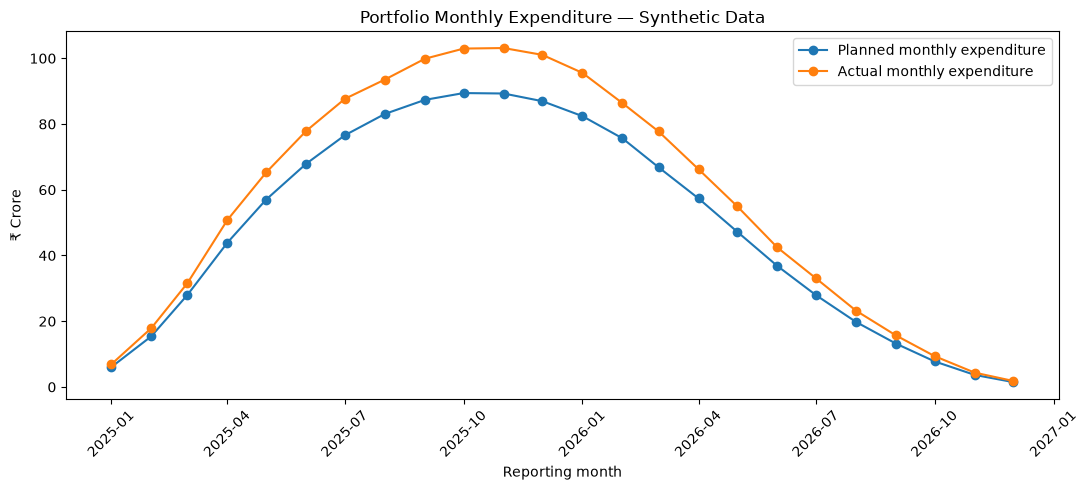

In [49]:
monthly_portfolio = (
    data.groupby("month", as_index=False)
        .agg(
            planned_expenditure_cr=("planned_cost_month_cr", "sum"),
            actual_expenditure_cr=("actual_cost_month_cr", "sum"),
            planned_progress_increment_pct=("planned_progress_increment_pct", "mean"),
            actual_progress_increment_pct=("actual_progress_increment_pct", "mean"),
            average_delay_days=("delay_days", "mean"),
        )
)

plt.figure(figsize=(11, 5))
plt.plot(monthly_portfolio["month"], monthly_portfolio["planned_expenditure_cr"], marker="o", label="Planned monthly expenditure")
plt.plot(monthly_portfolio["month"], monthly_portfolio["actual_expenditure_cr"], marker="o", label="Actual monthly expenditure")
plt.title("Portfolio Monthly Expenditure — Synthetic Data")
plt.ylabel("₹ Crore")
plt.xlabel("Reporting month")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "v2_01_monthly_expenditure.png", dpi=160, bbox_inches="tight")
plt.show()

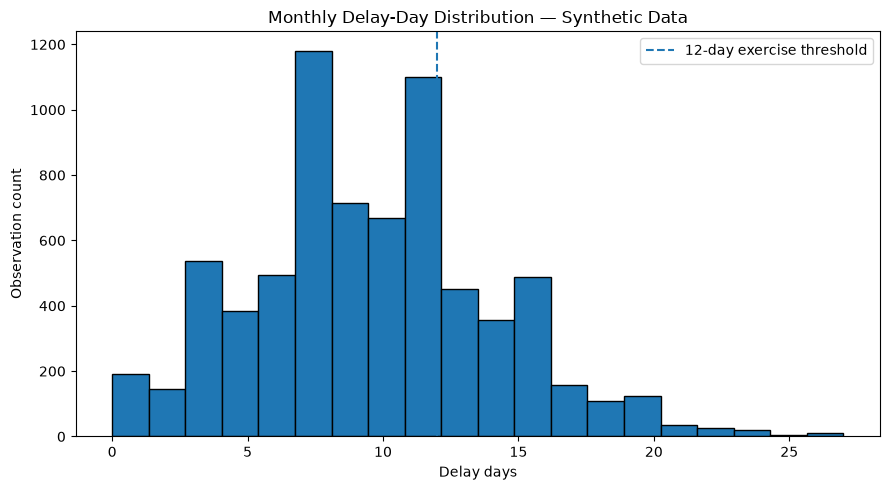

Share of records with delay >= 12 days: 0.319


In [50]:
plt.figure(figsize=(9, 5))
plt.hist(data["delay_days"], bins=20, edgecolor="black")
plt.axvline(12, linestyle="--", label="12-day exercise threshold")
plt.title("Monthly Delay-Day Distribution — Synthetic Data")
plt.xlabel("Delay days")
plt.ylabel("Observation count")
plt.legend()
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "v2_02_delay_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

print("Share of records with delay >= 12 days:", round((data["delay_days"] >= 12).mean(), 3))

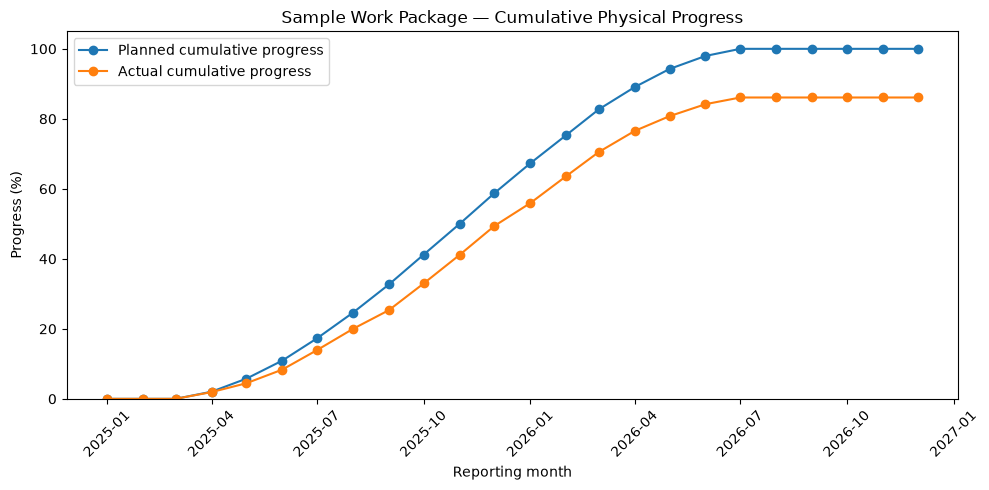

In [51]:
sample_series = data[
    (data["project_id"] == "PRJ-001")
    & (data["work_category"] == "RCC")
].sort_values("month")

plt.figure(figsize=(10, 5))
plt.plot(sample_series["month"], sample_series["planned_progress_pct"], marker="o", label="Planned cumulative progress")
plt.plot(sample_series["month"], sample_series["actual_progress_pct"], marker="o", label="Actual cumulative progress")
plt.title("Sample Work Package — Cumulative Physical Progress")
plt.ylabel("Progress (%)")
plt.xlabel("Reporting month")
plt.ylim(0, 105)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "v2_03_sample_progress_curve.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Data dictionary

The dictionary distinguishes observable project-control inputs from simulator-only diagnostics. The latter are excluded from modelling.

In [52]:
data_dictionary = pd.DataFrame([
    ("project_id", "Project identifier", "Categorical", "Observable"),
    ("project_name", "Project display name", "Categorical", "Observable"),
    ("contractor", "Assigned synthetic contractor", "Categorical", "Observable"),
    ("work_category", "Work package / discipline", "Categorical", "Observable"),
    ("month", "Monthly reporting period", "Date", "Observable"),
    ("month_index", "Sequential month number", "Numeric", "Observable"),
    ("contract_value_cr", "Project contract value, ₹ crore", "Numeric", "Observable"),
    ("package_budget_cr", "Work-package budget, ₹ crore", "Numeric", "Observable"),
    ("baseline_start_month", "Approved baseline start month index", "Numeric", "Known baseline"),
    ("baseline_duration_months", "Approved baseline duration", "Numeric", "Known baseline"),
    ("planned_progress_increment_pct", "Planned progress in the current month", "Numeric", "Known baseline"),
    ("planned_progress_pct", "Cumulative planned progress", "Numeric", "Known baseline"),
    ("actual_progress_increment_pct", "Actual progress achieved in current month", "Numeric", "Observed outcome"),
    ("actual_progress_pct", "Cumulative actual physical progress", "Numeric", "Observed outcome"),
    ("planned_cost_month_cr", "Planned current-month expenditure, ₹ crore", "Numeric", "Known baseline"),
    ("actual_cost_month_cr", "Actual current-month expenditure, ₹ crore", "Numeric", "Observed outcome"),
    ("cumulative_actual_cost_cr", "Cumulative actual expenditure, ₹ crore", "Numeric", "Observed outcome"),
    ("delay_days", "Recorded delay days in current reporting month", "Numeric", "Observed outcome"),
    ("labour_shortage_pct", "Estimated labour shortage percentage", "Numeric", "Observed driver"),
    ("procurement_delay_days", "Procurement-related delay days", "Numeric", "Observed driver"),
    ("design_change_count", "Count of design changes recorded in month", "Numeric", "Observed driver"),
    ("material_price_index", "Synthetic material-price index", "Numeric", "Observed driver"),
    ("rainfall_mm", "Synthetic monthly rainfall, millimetres", "Numeric", "Observed driver"),
    ("risk_state_simulated", "Latent project risk state used by simulator", "Numeric", "SIMULATOR ONLY — EXCLUDE"),
    ("productivity_factor_simulated", "Latent productivity multiplier used by simulator", "Numeric", "SIMULATOR ONLY — EXCLUDE"),
    ("PV_cr", "Cumulative planned value, ₹ crore", "Numeric", "Derived EVM"),
    ("EV_cr", "Cumulative earned value, ₹ crore", "Numeric", "Derived EVM"),
    ("AC_cr", "Cumulative actual cost, ₹ crore", "Numeric", "Derived EVM"),
    ("SV_cr", "Schedule variance = EV − PV, ₹ crore", "Numeric", "Derived EVM"),
    ("CV_cr", "Cost variance = EV − AC, ₹ crore", "Numeric", "Derived EVM"),
    ("SPI", "Schedule performance index = EV / PV", "Numeric", "Derived EVM"),
    ("CPI", "Cost performance index = EV / AC", "Numeric", "Derived EVM"),
], columns=["column", "definition", "data_type", "availability"])

display(data_dictionary)


,column,definition,data_type,availability
0,project_id,Project identifier,Categorical,Observable
1,project_name,Project display name,Categorical,Observable
2,contractor,Assigned synthetic contractor,Categorical,Observable
3,work_category,Work package / discipline,Categorical,Observable
4,month,Monthly reporting period,Date,Observable
5,month_index,Sequential month number,Numeric,Observable
6,contract_value_cr,"Project contract value, ₹ crore",Numeric,Observable
7,package_budget_cr,"Work-package budget, ₹ crore",Numeric,Observable
8,baseline_start_month,Approved baseline start month index,Numeric,Known baseline
9,baseline_duration_months,Approved baseline duration,Numeric,Known baseline


## 8. Export Version 2 data and quality artifacts

All Version 2 outputs use separate directories. Existing Version 1 outputs are not overwritten.

In [53]:
dataset_path = DATA_DIR / "construction_project_monthly_v2.csv"
quality_path = OUTPUT_DIR / "data_quality_report_v2.csv"
dictionary_path = OUTPUT_DIR / "data_dictionary_v2.csv"
summary_path = OUTPUT_DIR / "project_month_summary_v2.csv"

data.to_csv(dataset_path, index=False)
pd.DataFrame([quality_report]).to_csv(quality_path, index=False)
data_dictionary.to_csv(dictionary_path, index=False)
monthly_portfolio.to_csv(summary_path, index=False)

print("Saved:")
for path in [dataset_path, quality_path, dictionary_path, summary_path]:
    print("-", path.relative_to(PROJECT_ROOT), f"({path.stat().st_size:,} bytes)")

Saved:
- data_v2/construction_project_monthly_v2.csv (3,116,598 bytes)
- outputs_v2/data_quality_report_v2.csv (543 bytes)
- outputs_v2/data_dictionary_v2.csv (2,435 bytes)
- outputs_v2/project_month_summary_v2.csv (2,465 bytes)


## 9. Phase 1 completion checklist

- [x] Version 1 archived without modification.
- [x] Version 2 uses a larger, reproducible synthetic dataset.
- [x] Monthly and cumulative cost measures are distinct.
- [x] Monthly and cumulative progress measures are distinct.
- [x] EVM metrics are derived from cumulative values.
- [x] Data grain, monotonicity and financial reconciliation are checked.
- [x] Simulator-only variables are explicitly identified and excluded from model features.
- [x] Dataset and data dictionary are exported separately from Version 1.

### Next phase: predictive feature engineering and temporal validation

We will create next-month targets using grouped time shifts, construct lag and rolling features, define the chronological train/validation/test windows, and establish simple baselines before fitting machine-learning models.

**Interview checkpoint:** Be ready to explain why monthly expenditure is a flow variable, cumulative actual cost is a stock-to-date measure, and why the forecast origin determines which features are valid.

## Phase 2A: Predictive target engineering, features and temporal splits

This section converts the validated monthly panel into supervised-learning examples. Each row represents a **forecast made at the end of month _t_** for the same project-work-category in month _t + 1_.

### Prediction target
- `target_delay_next_month_days`: next month's recorded delay days.
- `target_delay_next_month`: 1 when next month's delay is at least 12 days, otherwise 0.

We also create next-month monthly expenditure and progress-increment targets now, so the three prediction tasks share one consistent forecast origin.

### Information boundary
Features may use current-month observations because the forecast is issued at month-end. The approved next-month planned cost and planned progress are treated as known-future baseline inputs. Next-month actual outcomes and simulator-only columns are excluded.

> **Important evaluation scope:** these splits test forecasting future months for the same synthetic projects and work packages. They do not test generalisation to entirely unseen projects.


### 2A.1 Create next-month targets with a grouped time shift

A normal `shift(-1)` on the whole dataframe could accidentally move outcomes across project or work-package boundaries. We therefore group by `project_id` and `work_category`, sort by month, and shift within each series. The final month in each series has no following-month target and is intentionally excluded from modelling.


In [54]:
# Rebuild a clean, chronologically ordered modelling panel from the Phase 1 dataset.
model_data = data.copy()
model_data['month'] = pd.to_datetime(model_data['month'])
model_data = model_data.sort_values(
    ['project_id', 'work_category', 'month']
).reset_index(drop=True)

SERIES_KEYS = ['project_id', 'work_category']
grouped = model_data.groupby(SERIES_KEYS, sort=False)

model_data['target_month'] = grouped['month'].shift(-1)
model_data['target_delay_next_month_days'] = grouped['delay_days'].shift(-1)
model_data['target_delay_next_month'] = (
    model_data['target_delay_next_month_days'].ge(12)
    .where(model_data['target_delay_next_month_days'].notna())
    .astype('float')
)
model_data['target_cost_next_month_cr'] = grouped['actual_cost_month_cr'].shift(-1)
model_data['target_progress_next_month_pct'] = grouped['actual_progress_increment_pct'].shift(-1)

# These approved baseline values are assumed to be available at forecast time.
model_data['known_next_month_planned_cost_cr'] = grouped['planned_cost_month_cr'].shift(-1)
model_data['known_next_month_planned_progress_pct'] = grouped['planned_progress_increment_pct'].shift(-1)

# Keep only rows for which a next-month outcome exists.
supervised = model_data.loc[model_data['target_month'].notna()].copy()

print('Supervised rows:', len(supervised))
print('Unique project-work-package series:', supervised.groupby(SERIES_KEYS).ngroups)
print('Forecast-origin months:', supervised['month_index'].min(), 'to', supervised['month_index'].max())
print('Target months:', supervised['target_month'].min().date(), 'to', supervised['target_month'].max().date())
print('Delay-positive share:', round(supervised['target_delay_next_month'].mean(), 3))

assert len(supervised) == 30 * 10 * 23
assert supervised['target_delay_next_month'].notna().all()
assert (supervised['target_month'] > supervised['month']).all()
assert (supervised.groupby(SERIES_KEYS)['month_index'].diff().dropna() == 1).all()
display(supervised[[
    'project_id', 'work_category', 'month', 'target_month',
    'delay_days', 'target_delay_next_month_days', 'target_delay_next_month',
    'known_next_month_planned_cost_cr', 'target_cost_next_month_cr',
    'known_next_month_planned_progress_pct', 'target_progress_next_month_pct'
]].head(10))

Supervised rows: 6900
Unique project-work-package series: 300
Forecast-origin months: 1 to 23
Target months: 2025-02-01 to 2026-12-01
Delay-positive share: 0.322


,project_id,work_category,month,target_month,delay_days,target_delay_next_month_days,target_delay_next_month,known_next_month_planned_cost_cr,target_cost_next_month_cr,known_next_month_planned_progress_pct,target_progress_next_month_pct
0,PRJ-001,Earthwork,2025-01-01,2025-02-01,4,5.000,0.000,0.045,0.047,1.698,1.404
1,PRJ-001,Earthwork,2025-02-01,2025-03-01,5,5.000,0.000,0.077,0.081,2.887,2.668
2,PRJ-001,Earthwork,2025-03-01,2025-04-01,5,4.000,0.000,0.105,0.114,3.935,2.521
3,PRJ-001,Earthwork,2025-04-01,2025-05-01,4,7.000,0.000,0.129,0.144,4.844,3.196
4,PRJ-001,Earthwork,2025-05-01,2025-06-01,7,5.000,0.000,0.149,0.154,5.613,4.677
5,PRJ-001,Earthwork,2025-06-01,2025-07-01,5,6.000,0.000,0.166,0.173,6.242,4.785
6,PRJ-001,Earthwork,2025-07-01,2025-08-01,6,5.000,0.000,0.179,0.202,6.731,5.483
7,PRJ-001,Earthwork,2025-08-01,2025-09-01,5,5.000,0.000,0.188,0.199,7.080,5.270
8,PRJ-001,Earthwork,2025-09-01,2025-10-01,5,5.000,0.000,0.194,0.202,7.290,5.927
9,PRJ-001,Earthwork,2025-10-01,2025-11-01,5,8.000,0.000,0.196,0.224,7.360,6.233


### 2A.2 Engineer features available at the forecast origin

We create: **(a)** current-state features, **(b)** one-month lags, **(c)** trailing three-month averages, **(d)** schedule variance context, and **(e)** next-month approved baseline inputs. Lag and rolling calculations are performed separately for each project-work-package series.

The trailing average includes the current month because the forecast is made after month _t_ closes. It never includes month _t + 1_.


In [55]:
# Current schedule position and progress gap. Positive gap means planned cumulative progress
# is ahead of actual cumulative progress.
supervised['progress_gap_pct'] = (
    supervised['planned_progress_pct'] - supervised['actual_progress_pct']
)

# Current EVM indices are observable at the end of the forecast-origin month.
# Their undefined early-project values will be imputed inside the model pipeline later.

ROLLING_SOURCE_COLUMNS = [
    'delay_days',
    'actual_progress_increment_pct',
    'actual_cost_month_cr',
    'labour_shortage_pct',
    'procurement_delay_days',
    'design_change_count',
    'material_price_index',
    'rainfall_mm',
]

for column in ROLLING_SOURCE_COLUMNS:
    supervised[f'{column}_lag_1'] = (
        supervised.groupby(SERIES_KEYS, sort=False)[column].shift(1)
    )
    supervised[f'{column}_rolling_mean_3'] = (
        supervised.groupby(SERIES_KEYS, sort=False)[column]
        .transform(lambda values: values.rolling(window=3, min_periods=1).mean())
    )

# Cyclical calendar terms let a model represent recurring seasonal patterns.
month_number = supervised['month'].dt.month
supervised['month_sin'] = np.sin(2 * np.pi * month_number / 12)
supervised['month_cos'] = np.cos(2 * np.pi * month_number / 12)

print('Feature engineering complete.')
print('Rows:', len(supervised))
print('Columns:', len(supervised.columns))
display(supervised[[
    'project_id', 'work_category', 'month', 'delay_days',
    'delay_days_lag_1', 'delay_days_rolling_mean_3',
    'actual_cost_month_cr_lag_1', 'actual_cost_month_cr_rolling_mean_3',
    'progress_gap_pct', 'known_next_month_planned_cost_cr'
]].head(12))

Feature engineering complete.
Rows: 6900
Columns: 58


,project_id,work_category,month,delay_days,delay_days_lag_1,delay_days_rolling_mean_3,actual_cost_month_cr_lag_1,actual_cost_month_cr_rolling_mean_3,progress_gap_pct,known_next_month_planned_cost_cr
0,PRJ-001,Earthwork,2025-01-01,4,NaN,4.000,NaN,0.000,0.000,0.045
1,PRJ-001,Earthwork,2025-02-01,5,4.000,4.500,0.000,0.024,0.295,0.077
2,PRJ-001,Earthwork,2025-03-01,5,5.000,4.667,0.047,0.043,0.513,0.105
3,PRJ-001,Earthwork,2025-04-01,4,5.000,4.667,0.081,0.081,1.928,0.129
4,PRJ-001,Earthwork,2025-05-01,7,4.000,5.333,0.114,0.113,3.576,0.149
5,PRJ-001,Earthwork,2025-06-01,5,7.000,5.333,0.144,0.137,4.511,0.166
6,PRJ-001,Earthwork,2025-07-01,6,5.000,6.000,0.154,0.157,5.968,0.179
7,PRJ-001,Earthwork,2025-08-01,5,6.000,5.333,0.173,0.176,7.216,0.188
8,PRJ-001,Earthwork,2025-09-01,5,5.000,5.333,0.202,0.191,9.026,0.194
9,PRJ-001,Earthwork,2025-10-01,5,5.000,5.000,0.199,0.201,10.389,0.196


### 2A.3 Define the modelling feature set and audit leakage

The feature list is explicit rather than selecting every numeric column automatically. This is safer because the dataset contains targets and simulator-only diagnostics. We deliberately exclude `target_*`, `target_month`, `risk_state_simulated`, and `productivity_factor_simulated`.

The next-month planned cost and planned progress are included as known-future baseline information. Next-month actual cost, progress and delay are not features.


In [56]:
CATEGORICAL_FEATURES = [
    'project_id', 'contractor', 'work_category'
]

NUMERIC_FEATURES = [
    'month_index', 'contract_value_cr', 'package_budget_cr',
    'baseline_start_month', 'baseline_duration_months',
    'planned_progress_pct', 'actual_progress_pct', 'progress_gap_pct',
    'planned_cost_month_cr', 'actual_cost_month_cr',
    'delay_days', 'labour_shortage_pct', 'procurement_delay_days',
    'design_change_count', 'material_price_index', 'rainfall_mm',
    'SPI', 'CPI', 'month_sin', 'month_cos',
    'known_next_month_planned_cost_cr',
    'known_next_month_planned_progress_pct',
]

for column in ROLLING_SOURCE_COLUMNS:
    NUMERIC_FEATURES.extend([f'{column}_lag_1', f'{column}_rolling_mean_3'])

FEATURE_COLUMNS = CATEGORICAL_FEATURES + NUMERIC_FEATURES

forbidden_feature_tokens = [
    'target_', 'risk_state_simulated', 'productivity_factor_simulated'
]
assert not any(
    token in feature for feature in FEATURE_COLUMNS for token in forbidden_feature_tokens
), 'A target or simulator-only field has entered the feature list.'
assert not set(FEATURE_COLUMNS).intersection({
    'target_month', 'target_delay_next_month_days', 'target_delay_next_month',
    'target_cost_next_month_cr', 'target_progress_next_month_pct',
    'risk_state_simulated', 'productivity_factor_simulated'
})

missing_feature_columns = sorted(set(FEATURE_COLUMNS) - set(supervised.columns))
assert not missing_feature_columns, f'Missing feature columns: {missing_feature_columns}'

print('Total features:', len(FEATURE_COLUMNS))
print('Categorical features:', CATEGORICAL_FEATURES)
print('Numeric features:', len(NUMERIC_FEATURES))
print('Leakage audit passed: target and simulator-only columns are excluded.')
display(pd.DataFrame({'feature': FEATURE_COLUMNS, 'type': [
    'categorical' if c in CATEGORICAL_FEATURES else 'numeric' for c in FEATURE_COLUMNS
]}))

Total features: 41
Categorical features: ['project_id', 'contractor', 'work_category']
Numeric features: 38
Leakage audit passed: target and simulator-only columns are excluded.


,feature,type
0,project_id,categorical
1,contractor,categorical
2,work_category,categorical
3,month_index,numeric
4,contract_value_cr,numeric
5,package_budget_cr,numeric
6,baseline_start_month,numeric
7,baseline_duration_months,numeric
8,planned_progress_pct,numeric
9,actual_progress_pct,numeric


### 2A.4 Create chronological train, validation and test windows

We split by the **forecast-origin month**, not by randomly shuffling rows. That preserves the real forecasting order.

| Split | Forecast-origin month index | Outcome months predicted |
|---|---:|---|
| Train | 1–15 | February 2025–April 2026 |
| Validation | 16–19 | May–August 2026 |
| Test | 20–23 | September–December 2026 |

The final test forecast origin is month 23, whose target is month 24 (December 2026). The validation and test windows are strictly later than the training window. We will use validation for model/threshold decisions and reserve test for final evaluation.


In [57]:
TRAIN_END_MONTH = 15
VALIDATION_END_MONTH = 19
TEST_END_MONTH = 23

train_df = supervised.loc[supervised['month_index'].between(1, TRAIN_END_MONTH)].copy()
validation_df = supervised.loc[
    supervised['month_index'].between(TRAIN_END_MONTH + 1, VALIDATION_END_MONTH)
].copy()
test_df = supervised.loc[
    supervised['month_index'].between(VALIDATION_END_MONTH + 1, TEST_END_MONTH)
].copy()

split_summary = pd.DataFrame([
    {
        'split': split_name,
        'rows': len(frame),
        'forecast_origin_start': frame['month'].min().date(),
        'forecast_origin_end': frame['month'].max().date(),
        'target_month_start': frame['target_month'].min().date(),
        'target_month_end': frame['target_month'].max().date(),
        'delay_positive_rate': frame['target_delay_next_month'].mean(),
    }
    for split_name, frame in [
        ('train', train_df), ('validation', validation_df), ('test', test_df)
    ]
])
display(split_summary)

assert len(train_df) == 30 * 10 * 15
assert len(validation_df) == 30 * 10 * 4
assert len(test_df) == 30 * 10 * 4
assert train_df['month_index'].max() < validation_df['month_index'].min()
assert validation_df['month_index'].max() < test_df['month_index'].min()
assert train_df['target_month'].max() < validation_df['target_month'].min()
assert validation_df['target_month'].max() < test_df['target_month'].min()

X_train = train_df[FEATURE_COLUMNS].copy()
y_train = train_df['target_delay_next_month'].astype(int).copy()
X_validation = validation_df[FEATURE_COLUMNS].copy()
y_validation = validation_df['target_delay_next_month'].astype(int).copy()
X_test = test_df[FEATURE_COLUMNS].copy()
y_test = test_df['target_delay_next_month'].astype(int).copy()

print('Chronological split checks passed.')
print('X_train:', X_train.shape, '| y_train:', y_train.shape)
print('X_validation:', X_validation.shape, '| y_validation:', y_validation.shape)
print('X_test:', X_test.shape, '| y_test:', y_test.shape)

,split,rows,forecast_origin_start,forecast_origin_end,target_month_start,target_month_end,delay_positive_rate
0,train,4500,2025-01-01,2026-03-01,2025-02-01,2026-04-01,0.303
1,validation,1200,2026-04-01,2026-07-01,2026-05-01,2026-08-01,0.330
2,test,1200,2026-08-01,2026-11-01,2026-09-01,2026-12-01,0.384


Chronological split checks passed.
X_train: (4500, 41) | y_train: (4500,)
X_validation: (1200, 41) | y_validation: (1200,)
X_test: (1200, 41) | y_test: (1200,)


### 2A.5 Save the engineered modelling table and split summary

We export the supervised table for reproducibility. It contains targets for analysis and model development, so it must not be mistaken for a raw feature-only production input table. The feature list is exported separately to make the modelling contract explicit.


In [58]:
supervised_path = OUTPUT_DIR / 'supervised_next_month_dataset_v2.csv'
feature_list_path = OUTPUT_DIR / 'delay_model_feature_list_v2.csv'
split_summary_path = OUTPUT_DIR / 'temporal_split_summary_v2.csv'

supervised.to_csv(supervised_path, index=False)
pd.DataFrame({
    'feature': FEATURE_COLUMNS,
    'feature_type': [
        'categorical' if c in CATEGORICAL_FEATURES else 'numeric'
        for c in FEATURE_COLUMNS
    ],
}).to_csv(feature_list_path, index=False)
split_summary.to_csv(split_summary_path, index=False)

print('Saved:')
for output_path in [supervised_path, feature_list_path, split_summary_path]:
    print('-', output_path.relative_to(PROJECT_ROOT))

Saved:
- outputs_v2/supervised_next_month_dataset_v2.csv
- outputs_v2/delay_model_feature_list_v2.csv
- outputs_v2/temporal_split_summary_v2.csv


### Phase 2A checkpoint — explain these decisions

1. Why is the target created with `groupby(['project_id', 'work_category']).shift(-1)` instead of a dataframe-wide shift?
2. Why can next month's planned cost be a feature while next month's actual cost cannot?
3. Why do we split by time instead of using a random train/test split?
4. What does the 12-day classification threshold mean, and why is it not a universal contractual standard?

**Next: Phase 2B** will build a simple, reproducible baseline classifier, then a preprocessing/model pipeline. We will compare it using precision, recall, F1, ROC-AUC and especially PR-AUC, and select any operating threshold using validation data—not the test set.


## Phase 2B: Delay-risk classification — baseline and first models

**Business question:** At the end of month *t*, estimate whether a project-work-category package will record at least 12 delay days in month *t+1*.

The 12-day cut-off is a portfolio modelling convention, not a universal contractual definition. This is an early-warning model: the cost of missing a genuinely delayed package may be greater than the cost of reviewing a false alarm. We will therefore examine recall and precision together, and later use an F-beta score with beta greater than 1 to reflect recall emphasis.

**Modelling protocol:** fit preprocessing and models on training data only; use validation data for model comparison and threshold selection; evaluate the selected approach once on the held-out test period. The test set must not guide feature selection, model choice or threshold tuning.

### 2B.1 Define evaluation metrics

- **Precision:** of packages flagged as high risk, what fraction actually crossed the delay threshold?
- **Recall:** of packages that crossed the delay threshold, what fraction did the model identify?
- **F1:** harmonic mean of precision and recall, weighting them equally.
- **F2:** harmonic mean that weights recall twice as strongly as precision.
- **ROC-AUC:** ranking quality across classification thresholds.
- **Average precision (AP):** summarises the precision-recall curve and is particularly useful when classes are imbalanced.

Accuracy alone is not sufficient: a model that predicts “no delay” for every row could appear accurate while identifying no delayed packages.

In [59]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, fbeta_score, precision_score,
    recall_score, roc_auc_score, precision_recall_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

print('Training positive rate:', round(y_train.mean(), 3))
print('Validation positive rate:', round(y_validation.mean(), 3))
print('Test positive rate:', round(y_test.mean(), 3))
print('Feature matrix shapes:', X_train.shape, X_validation.shape, X_test.shape)

assert X_train.columns.tolist() == FEATURE_COLUMNS
assert X_validation.columns.tolist() == FEATURE_COLUMNS
assert X_test.columns.tolist() == FEATURE_COLUMNS
assert set(y_train.unique()).issubset({0, 1})
assert set(y_validation.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

Training positive rate: 0.303
Validation positive rate: 0.33
Test positive rate: 0.384
Feature matrix shapes: (4500, 41) (1200, 41) (1200, 41)


### 2B.2 Establish a naive baseline

The baseline predicts the majority class from the training data for every future observation. It is intentionally simple. It tells us whether the machine-learning models provide value beyond a trivial “always predict the majority class” rule.

A zero-recall baseline is not useful as an operational warning system, even if its accuracy looks respectable.

In [60]:
baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train, y_train)
baseline_prediction = baseline_model.predict(X_validation)

baseline_validation_metrics = {
    'model': 'Majority-class baseline',
    'threshold': np.nan,
    'accuracy': accuracy_score(y_validation, baseline_prediction),
    'precision': precision_score(y_validation, baseline_prediction, zero_division=0),
    'recall': recall_score(y_validation, baseline_prediction, zero_division=0),
    'f1': f1_score(y_validation, baseline_prediction, zero_division=0),
    'f2': fbeta_score(y_validation, baseline_prediction, beta=2, zero_division=0),
}
display(pd.DataFrame([baseline_validation_metrics]))
display(pd.DataFrame(
    confusion_matrix(y_validation, baseline_prediction),
    index=['Actual no delay', 'Actual delay'],
    columns=['Predicted no delay', 'Predicted delay']
))

,model,threshold,accuracy,precision,recall,f1,f2
0,Majority-class baseline,NaN,0.670,0.000,0.000,0.000,0.000


,Predicted no delay,Predicted delay
Actual no delay,804,0
Actual delay,396,0


### 2B.3 Build leakage-safe preprocessing pipelines

Numerical fields are median-imputed and standardised for Logistic Regression. Categorical fields are imputed with the most frequent training value and one-hot encoded. Unknown categories at validation/test time are ignored rather than causing a failure.

The preprocessing steps are inside each scikit-learn `Pipeline`. This is important: imputers, scaling parameters and category vocabularies are learned from training data only, not from the full dataset.

In [61]:
numeric_preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_preprocessor, NUMERIC_FEATURES),
    ('categorical', categorical_preprocessor, CATEGORICAL_FEATURES),
], remainder='drop')

logistic_pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=RANDOM_STATE,
    )),
])

random_forest_pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=3,
        max_features='sqrt',
        class_weight='balanced_subsample',
        random_state=RANDOM_STATE,
        n_jobs=1,
    )),
])

print('Pipelines defined. No preprocessing has been fitted on validation or test data.')

Pipelines defined. No preprocessing has been fitted on validation or test data.


### 2B.4 Train models and compare validation ranking performance

We fit both models on the training window. We compare ROC-AUC and average precision on the validation window. Average precision is especially informative here because the positive class is not the majority class.

At this stage, we use predicted probabilities for ranking. We have not yet chosen an operational alert threshold.

,model,validation_roc_auc,validation_average_precision
0,Random Forest,0.793,0.621
1,Logistic Regression,0.781,0.621


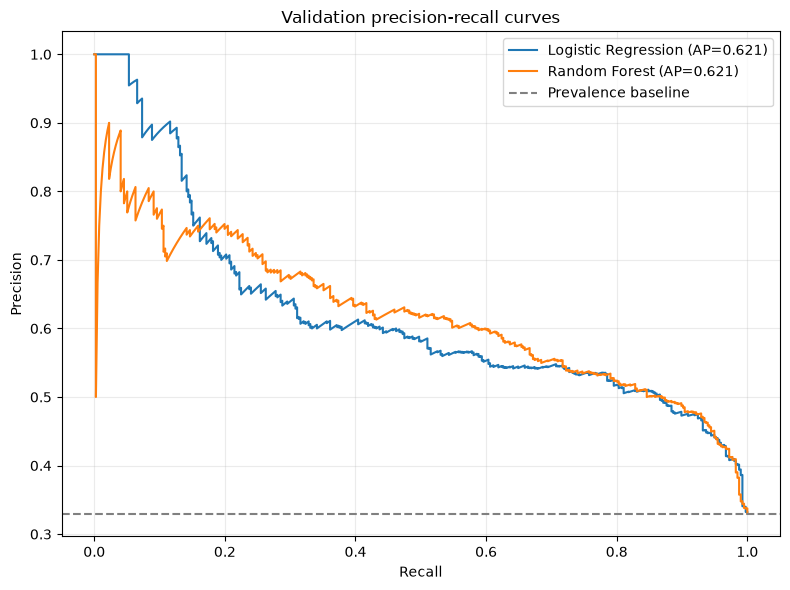

In [62]:
classification_models = {
    'Logistic Regression': logistic_pipeline,
    'Random Forest': random_forest_pipeline,
}

validation_probabilities = {}
validation_ranking_rows = []

for model_name, model in classification_models.items():
    model.fit(X_train, y_train)
    probabilities = model.predict_proba(X_validation)[:, 1]
    validation_probabilities[model_name] = probabilities
    validation_ranking_rows.append({
        'model': model_name,
        'validation_roc_auc': roc_auc_score(y_validation, probabilities),
        'validation_average_precision': average_precision_score(y_validation, probabilities),
    })

validation_ranking = pd.DataFrame(validation_ranking_rows).sort_values(
    'validation_average_precision', ascending=False
).reset_index(drop=True)
display(validation_ranking)

plt.figure(figsize=(8, 6))
for model_name, probabilities in validation_probabilities.items():
    precision_values, recall_values, _ = precision_recall_curve(y_validation, probabilities)
    ap = average_precision_score(y_validation, probabilities)
    plt.plot(recall_values, precision_values, label=f'{model_name} (AP={ap:.3f})')
plt.axhline(y_validation.mean(), linestyle='--', color='grey', label='Prevalence baseline')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Validation precision-recall curves')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 2B.5 Evaluate a default 0.50 threshold

A probability threshold of 0.50 is a conventional starting point, not automatically the best operational threshold. We calculate precision, recall, F1 and F2 at 0.50 so that we have a transparent reference before threshold optimisation.

In [63]:
def classification_metrics(y_true, probabilities, threshold=0.50, model_name='model'):
    predictions = (np.asarray(probabilities) >= threshold).astype(int)
    return {
        'model': model_name,
        'threshold': threshold,
        'accuracy': accuracy_score(y_true, predictions),
        'precision': precision_score(y_true, predictions, zero_division=0),
        'recall': recall_score(y_true, predictions, zero_division=0),
        'f1': f1_score(y_true, predictions, zero_division=0),
        'f2': fbeta_score(y_true, predictions, beta=2, zero_division=0),
        'roc_auc': roc_auc_score(y_true, probabilities),
        'average_precision': average_precision_score(y_true, probabilities),
    }

validation_default_rows = [baseline_validation_metrics]
for model_name, probabilities in validation_probabilities.items():
    validation_default_rows.append(
        classification_metrics(y_validation, probabilities, 0.50, model_name)
    )
validation_default = pd.DataFrame(validation_default_rows)
display(validation_default)

,model,threshold,accuracy,precision,recall,f1,f2,roc_auc,average_precision
0,Majority-class baseline,NaN,0.670,0.000,0.000,0.000,0.000,NaN,NaN
1,Logistic Regression,0.500,0.703,0.533,0.785,0.635,0.718,0.781,0.621
2,Random Forest,0.500,0.724,0.618,0.429,0.507,0.457,0.793,0.621


### 2B.6 Select an alert threshold using validation data only

For an early-warning use case, missing a genuinely delayed package may be more harmful than asking the site team to review a false alarm. We therefore use **F2** as the threshold-selection criterion, which weights recall more heavily than precision.

This is a modelling choice, not a universal business rule. In a real PMC deployment, the threshold should be agreed with project leadership using intervention capacity, review cost and the consequence of missed delays. The test set remains untouched during this selection.

In [64]:
def choose_threshold_for_f2(y_true, probabilities):
    candidate_thresholds = np.linspace(0.05, 0.95, 181)
    rows = []
    for threshold in candidate_thresholds:
        predictions = (probabilities >= threshold).astype(int)
        rows.append({
            'threshold': threshold,
            'precision': precision_score(y_true, predictions, zero_division=0),
            'recall': recall_score(y_true, predictions, zero_division=0),
            'f1': f1_score(y_true, predictions, zero_division=0),
            'f2': fbeta_score(y_true, predictions, beta=2, zero_division=0),
        })
    curve = pd.DataFrame(rows)
    best = curve.sort_values(
        ['f2', 'precision', 'threshold'], ascending=[False, False, False]
    ).iloc[0]
    return float(best['threshold']), curve

threshold_results = {}
threshold_summary_rows = []
for model_name, probabilities in validation_probabilities.items():
    threshold, curve = choose_threshold_for_f2(y_validation, probabilities)
    threshold_results[model_name] = {'threshold': threshold, 'curve': curve}
    threshold_summary_rows.append({
        'model': model_name,
        'selected_threshold': threshold,
        'validation_precision': precision_score(
            y_validation, probabilities >= threshold, zero_division=0
        ),
        'validation_recall': recall_score(
            y_validation, probabilities >= threshold, zero_division=0
        ),
        'validation_f2': fbeta_score(
            y_validation, probabilities >= threshold, beta=2, zero_division=0
        ),
    })

threshold_summary = pd.DataFrame(threshold_summary_rows).sort_values(
    'validation_f2', ascending=False
).reset_index(drop=True)
display(threshold_summary)

best_model_name = validation_ranking.iloc[0]['model']
selected_model = classification_models[best_model_name]
selected_threshold = threshold_results[best_model_name]['threshold']
print('Selected model by validation average precision:', best_model_name)
print('Its F2-selected validation threshold:', round(selected_threshold, 3))

,model,selected_threshold,validation_precision,validation_recall,validation_f2
0,Random Forest,0.280,0.476,0.929,0.781
1,Logistic Regression,0.345,0.469,0.929,0.777


Selected model by validation average precision: Random Forest
Its F2-selected validation threshold: 0.28


### 2B.7 Final held-out test evaluation

The model family was selected by validation average precision, and its alert threshold was selected by validation F2. We now apply that frozen model and threshold to the test window once.

Do not tune the model after looking at these test results. If the result is unsatisfactory, any new modelling decision must be developed using training/validation data and assessed on a genuinely new future period.

,model,threshold,accuracy,precision,recall,f1,f2,roc_auc,average_precision,test_positive_rate
0,Random Forest,0.280,0.613,0.498,0.868,0.632,0.755,0.771,0.669,0.384


,Predicted no delay,Predicted delay
Actual no delay,335,404
Actual delay,61,400


                     precision    recall  f1-score   support

No delay >= 12 days       0.85      0.45      0.59       739
   Delay >= 12 days       0.50      0.87      0.63       461

           accuracy                           0.61      1200
          macro avg       0.67      0.66      0.61      1200
       weighted avg       0.71      0.61      0.61      1200



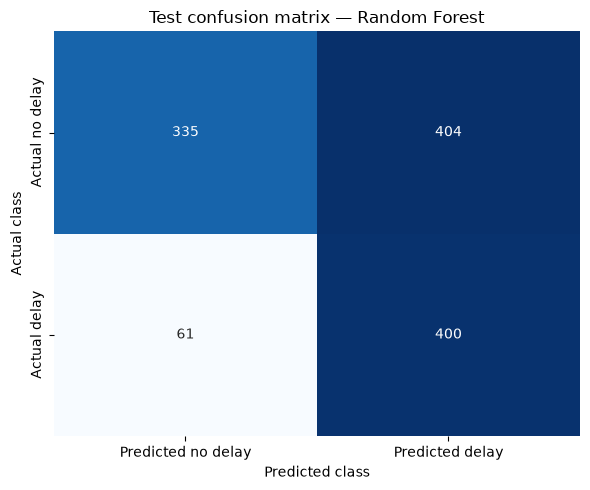

In [65]:
test_probabilities = selected_model.predict_proba(X_test)[:, 1]
test_metrics = classification_metrics(
    y_test, test_probabilities, selected_threshold, best_model_name
)
test_metrics['test_positive_rate'] = y_test.mean()
display(pd.DataFrame([test_metrics]))

test_predictions = (test_probabilities >= selected_threshold).astype(int)
test_confusion = confusion_matrix(y_test, test_predictions)
display(pd.DataFrame(
    test_confusion,
    index=['Actual no delay', 'Actual delay'],
    columns=['Predicted no delay', 'Predicted delay']
))

print(classification_report(
    y_test, test_predictions,
    target_names=['No delay >= 12 days', 'Delay >= 12 days'],
    zero_division=0,
))

plt.figure(figsize=(6, 5))
sns.heatmap(test_confusion, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted no delay', 'Predicted delay'],
            yticklabels=['Actual no delay', 'Actual delay'])
plt.title(f'Test confusion matrix — {best_model_name}')
plt.ylabel('Actual class')
plt.xlabel('Predicted class')
plt.tight_layout()
plt.show()

### 2B.8 Save Phase 2B model evaluation artifacts

We save the validation comparisons, threshold-selection results and held-out test metrics separately from Version 1. The selected estimator is retained in the notebook session; model persistence will be handled after we settle the modelling protocol and dependencies.

In [66]:
phase2b_validation_path = OUTPUT_DIR / 'delay_classifier_validation_comparison_v2.csv'
phase2b_threshold_path = OUTPUT_DIR / 'delay_classifier_threshold_selection_v2.csv'
phase2b_test_path = OUTPUT_DIR / 'delay_classifier_test_metrics_v2.csv'

validation_default.to_csv(phase2b_validation_path, index=False)
threshold_summary.to_csv(phase2b_threshold_path, index=False)
pd.DataFrame([test_metrics]).to_csv(phase2b_test_path, index=False)

print('Saved Phase 2B artifacts:')
for path in [phase2b_validation_path, phase2b_threshold_path, phase2b_test_path]:
    print('-', path.relative_to(PROJECT_ROOT))

Saved Phase 2B artifacts:
- outputs_v2/delay_classifier_validation_comparison_v2.csv
- outputs_v2/delay_classifier_threshold_selection_v2.csv
- outputs_v2/delay_classifier_test_metrics_v2.csv


### Phase 2B checkpoint — explain these decisions

1. Why is the majority-class baseline useful even if it has poor recall?
2. Why is preprocessing fitted inside a `Pipeline` rather than before the train/validation/test split?
3. Why are precision and recall more informative than accuracy for this early-warning task?
4. Why did we select the threshold on validation data rather than the test data?
5. What operational consequences follow from a false negative versus a false positive in a PMC setting?

**Important limitation:** This is a synthetic dataset generated by a known simulation process. Strong test metrics demonstrate that the pipeline can learn patterns in this simulated data; they do not establish real-world predictive performance. Before deployment, the model must be trained and independently validated on historical project data with reliable reporting dates, contractual delay definitions and a realistic intervention workflow.

## Phase 2C: Threshold optimisation, model explainability and calibration diagnostics

Phase 2B established a model and selected an alert threshold using validation data. This phase translates the classifier into an operational early-warning workflow.

We will:

1. Compare alert thresholds in terms of precision, recall and review workload.
2. Inspect the validation confusion matrix and quantify false-positive / false-negative counts.
3. Explain the selected pipeline with permutation importance on the original input features.
4. Check whether predicted probabilities are reasonably calibrated using validation data only.

**Data discipline:** the held-out test set was already used for the Phase 2B final evaluation. We will not use it to choose another threshold, explain features, or recalibrate the model. All Phase 2C diagnostics below use the validation window.

### 2C.1 Compare thresholds as an operational capacity decision

A threshold is not just a statistical setting. It controls how many work packages are sent to the PMC team for review.

- Lower threshold: usually more alerts, higher recall and more false positives.
- Higher threshold: usually fewer alerts, higher precision and more missed delays.

We compare a few transparent thresholds, including the F2-selected validation threshold. The final choice in a real project should reflect how many packages the project team can investigate and the relative consequences of missed delays versus unnecessary reviews.

In [67]:
# Build an operational threshold comparison on the validation window only.
threshold_candidates = sorted(set([
    0.25,
    float(selected_threshold),
    0.50,
    0.65,
]))

threshold_operating_rows = []
for threshold in threshold_candidates:
    predicted_alert = (validation_probabilities[best_model_name] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_validation, predicted_alert, labels=[0, 1]).ravel()
    threshold_operating_rows.append({
        'threshold': threshold,
        'precision': precision_score(y_validation, predicted_alert, zero_division=0),
        'recall': recall_score(y_validation, predicted_alert, zero_division=0),
        'f1': f1_score(y_validation, predicted_alert, zero_division=0),
        'f2': fbeta_score(y_validation, predicted_alert, beta=2, zero_division=0),
        'alerts': int(predicted_alert.sum()),
        'alert_rate_pct': 100 * predicted_alert.mean(),
        'false_positives': int(fp),
        'false_negatives': int(fn),
        'true_positives': int(tp),
        'true_negatives': int(tn),
    })

threshold_operating_table = pd.DataFrame(threshold_operating_rows).sort_values('threshold')
display(threshold_operating_table.round(3))

threshold_operating_path = OUTPUT_DIR / 'delay_threshold_operating_points_v2.csv'
threshold_operating_table.to_csv(threshold_operating_path, index=False)
print('Saved:', threshold_operating_path.relative_to(PROJECT_ROOT))

,threshold,precision,recall,f1,f2,alerts,alert_rate_pct,false_positives,false_negatives,true_positives,true_negatives
0,0.250,0.464,0.937,0.620,0.778,800,66.667,429,25,371,375
1,0.280,0.476,0.929,0.630,0.781,773,64.417,405,28,368,399
2,0.500,0.618,0.429,0.507,0.457,275,22.917,105,226,170,699
3,0.650,0.810,0.043,0.082,0.053,21,1.750,4,379,17,800


Saved: outputs_v2/delay_threshold_operating_points_v2.csv


### 2C.2 Inspect the validation confusion matrix and review workload

The validation confusion matrix shows the errors at the selected threshold before the final test period. In a PMC workflow:

- **False negative:** a package is not flagged but later crosses the delay threshold. This is a missed early warning.
- **False positive:** a package is flagged but does not cross the defined delay threshold. It still needs triage; it is not automatically a useful warning.

The model should support, not replace, engineering judgement. Review priority should also consider critical-path status, remaining float, cost exposure, safety and contractual milestones—where those fields are available and reliably recorded.

,Predicted no delay,Predicted delay
Actual no delay,399,405
Actual delay,28,368


,selected_model,selected_threshold,true_positives,false_positives,true_negatives,false_negatives,alerts_for_review,share_of_packages_flagged_pct,missed_delay_share_pct
0,Random Forest,0.280,368,405,399,28,773,64.417,7.071


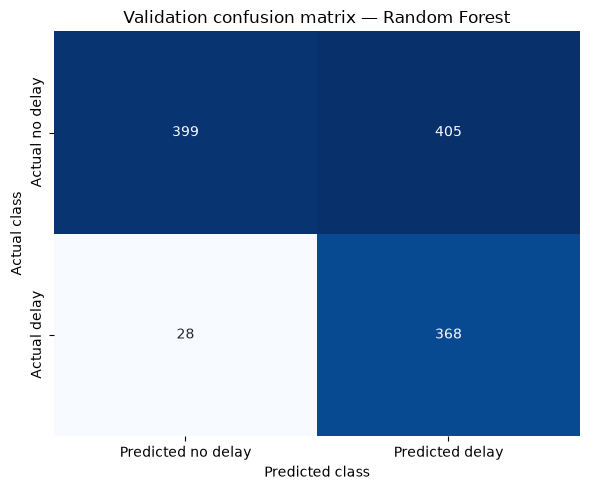

In [68]:
validation_selected_probabilities = validation_probabilities[best_model_name]
validation_selected_predictions = (validation_selected_probabilities >= selected_threshold).astype(int)
validation_confusion = confusion_matrix(
    y_validation, validation_selected_predictions, labels=[0, 1]
)
tn, fp, fn, tp = validation_confusion.ravel()

validation_confusion_df = pd.DataFrame(
    validation_confusion,
    index=['Actual no delay', 'Actual delay'],
    columns=['Predicted no delay', 'Predicted delay'],
)
display(validation_confusion_df)

validation_error_summary = pd.DataFrame([{
    'selected_model': best_model_name,
    'selected_threshold': selected_threshold,
    'true_positives': int(tp),
    'false_positives': int(fp),
    'true_negatives': int(tn),
    'false_negatives': int(fn),
    'alerts_for_review': int(tp + fp),
    'share_of_packages_flagged_pct': 100 * (tp + fp) / len(y_validation),
    'missed_delay_share_pct': 100 * fn / max(fn + tp, 1),
}])
display(validation_error_summary.round(3))

plt.figure(figsize=(6, 5))
sns.heatmap(validation_confusion, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted no delay', 'Predicted delay'],
            yticklabels=['Actual no delay', 'Actual delay'])
plt.title(f'Validation confusion matrix — {best_model_name}')
plt.ylabel('Actual class')
plt.xlabel('Predicted class')
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / 'v2_04_validation_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### 2C.3 Explain the model using permutation importance

Permutation importance asks: **How much does validation Average Precision deteriorate when one input feature is shuffled?**

The selected, already-fitted pipeline is evaluated on the validation set. Each raw input column is shuffled independently, and the change in Average Precision is measured. This works with both numerical and categorical input columns and explains the complete pipeline at the original feature level.

Interpretation cautions:

- A larger positive value means the model relied more on that feature for validation ranking performance.
- A value near zero means shuffling that feature had little measured effect in this experiment.
- A negative value can occur from sampling variability or redundant/correlated features.
- Importance is predictive association, not causation. It does not prove that changing a feature will change project delay.

,feature,importance_mean,importance_std
0,labour_shortage_pct_rolling_mean_3,0.051,0.009
1,labour_shortage_pct,0.040,0.003
2,labour_shortage_pct_lag_1,0.034,0.008
3,contractor,0.032,0.005
4,project_id,0.012,0.002
5,procurement_delay_days_rolling_mean_3,0.007,0.003
6,contract_value_cr,0.005,0.002
7,rainfall_mm_lag_1,0.005,0.002
8,procurement_delay_days,0.005,0.003
9,package_budget_cr,0.004,0.003


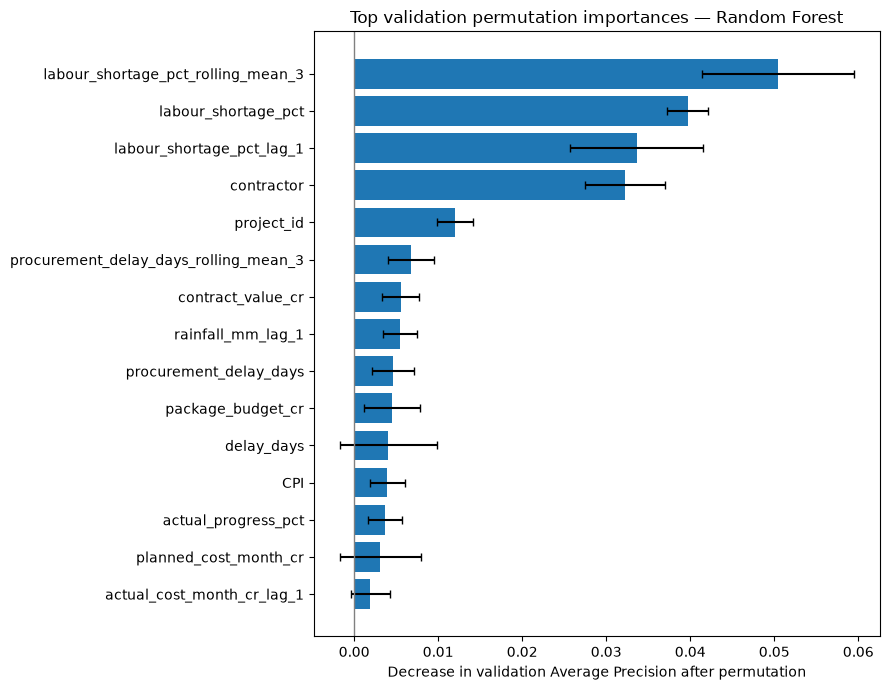

Saved: outputs_v2/delay_model_permutation_importance_v2.csv


In [69]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    selected_model,
    X_validation,
    y_validation,
    scoring='average_precision',
    n_repeats=4,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

permutation_importance_df = pd.DataFrame({
    'feature': FEATURE_COLUMNS,
    'importance_mean': permutation_result.importances_mean,
    'importance_std': permutation_result.importances_std,
}).sort_values('importance_mean', ascending=False).reset_index(drop=True)

display(permutation_importance_df.head(20).round(4))

importance_path = OUTPUT_DIR / 'delay_model_permutation_importance_v2.csv'
permutation_importance_df.to_csv(importance_path, index=False)

plot_importance = permutation_importance_df.head(15).sort_values('importance_mean')
plt.figure(figsize=(9, 7))
plt.barh(plot_importance['feature'], plot_importance['importance_mean'],
         xerr=plot_importance['importance_std'], capsize=3)
plt.axvline(0, color='grey', linewidth=1)
plt.xlabel('Decrease in validation Average Precision after permutation')
plt.title(f'Top validation permutation importances — {best_model_name}')
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / 'v2_05_delay_permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved:', importance_path.relative_to(PROJECT_ROOT))

### 2C.3.1 Interpret the leading features carefully

In this synthetic run, the strongest validation permutation-importance signals include the three-month rainfall average, material-price index and its rolling average, labour-shortage rolling average, project and contractor identifiers, recent progress, and approved next-month planned progress.

The prominence of `project_id` and `contractor` deserves special attention. These identifiers can help a model recognise patterns within the same known portfolio, which matches the current chronological experiment. However, a one-hot model may not generalise well to a completely new project or contractor it has never seen. A production evaluation should therefore include a separate **project-held-out** experiment and a comparison model that excludes identity columns. The current temporal test only measures future-month performance for project/work-package series already represented in training.

The simulation generated these relationships, so this feature ranking is a diagnostic of the synthetic process—not a construction-industry finding.

### 2C.4 Check probability calibration on validation data

Ranking and classification are different questions:

- Ranking asks whether delayed packages tend to receive higher scores than non-delayed packages.
- Calibration asks whether predicted probabilities correspond to observed event frequencies.

For example, among cases assigned a probability near 0.70, a well-calibrated model should experience the event roughly 70% of the time over a sufficiently large representative sample.

We report the Brier score and a reliability diagram on validation data. The Brier score is the mean squared error of predicted probabilities; lower is better, but it should be interpreted against the validation event rate and other models. This is a diagnostic only—we are not fitting a calibration adjustment in this phase.

,model,validation_brier_score,training_prevalence_constant_brier,validation_event_rate
0,Random Forest,0.174,0.222,0.330


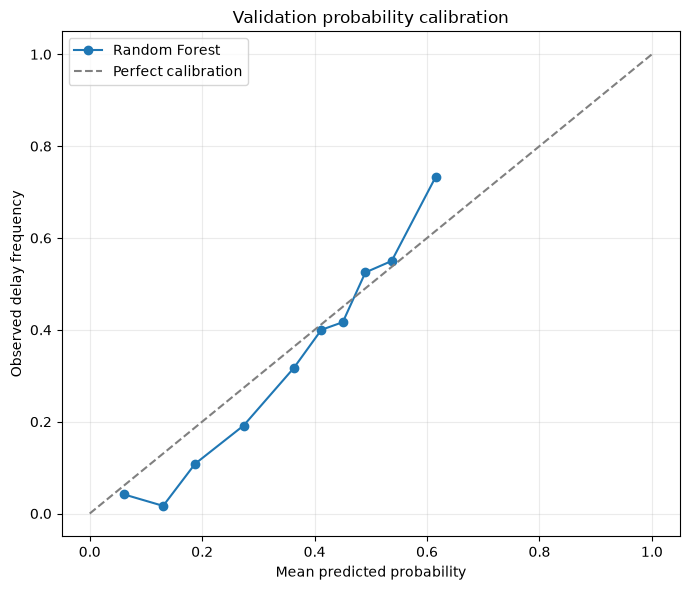

Saved: outputs_v2/delay_probability_calibration_v2.csv


In [70]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

validation_brier = brier_score_loss(y_validation, validation_selected_probabilities)
prevalence_probability = np.repeat(y_train.mean(), len(y_validation))
prevalence_brier = brier_score_loss(y_validation, prevalence_probability)

calibration_summary = pd.DataFrame([
    {
        'model': best_model_name,
        'validation_brier_score': validation_brier,
        'training_prevalence_constant_brier': prevalence_brier,
        'validation_event_rate': y_validation.mean(),
    }
])
display(calibration_summary.round(4))

observed_fraction, mean_predicted_probability = calibration_curve(
    y_validation,
    validation_selected_probabilities,
    n_bins=10,
    strategy='quantile',
)

plt.figure(figsize=(7, 6))
plt.plot(mean_predicted_probability, observed_fraction, marker='o', label=best_model_name)
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Perfect calibration')
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed delay frequency')
plt.title('Validation probability calibration')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / 'v2_06_delay_probability_calibration.png', dpi=150, bbox_inches='tight')
plt.show()

calibration_path = OUTPUT_DIR / 'delay_probability_calibration_v2.csv'
calibration_summary.to_csv(calibration_path, index=False)
print('Saved:', calibration_path.relative_to(PROJECT_ROOT))

### 2C.5 Phase 2C conclusions and limitations

At this point, we have a repeatable early-warning modelling workflow with:

- A threshold comparison that makes alert workload visible.
- Validation confusion-matrix counts that separate missed delays from unnecessary alerts.
- Permutation importance to explain which observed inputs contribute to model ranking.
- A calibration diagnostic to distinguish ranking quality from probability reliability.

**Do not describe permutation importance as causal impact. Do not describe an uncalibrated model score as a precise contractual probability.** Before operational deployment, validate on multiple real projects and future periods, confirm the contractual definition of delay, assess data quality and missingness, and agree alert capacity and escalation rules with project leadership.

### Phase 2C checkpoint — explain these decisions

1. Why can a lower alert threshold increase PMC review workload?
2. What is the operational difference between a false positive and a false negative?
3. Why does permutation importance not establish causality?
4. What does a calibration curve tell us that ROC-AUC does not?
5. Why did we use validation data—not the already evaluated test data—for these diagnostics?

## Phase 2D: PMC risk prioritisation under limited investigation capacity

The classifier produces a probability and a binary alert. A PMC team also needs an investigation queue. In this phase we retain the validation-selected probability threshold and rank flagged work packages so that the highest-priority cases are reviewed first.

**Important data limitation:** the current synthetic dataset does not contain critical-path status, downstream activity links, float, forecast completion-date impact, or cost-at-risk. We must not invent these fields. The first prioritisation prototype therefore uses two observable proxies available at the forecast origin:

1. **Package budget exposure:** larger package budgets represent greater financial exposure.
2. **Current schedule gap:** a larger positive gap between planned and actual cumulative progress indicates greater current schedule slippage.

Within each forecast-origin month, both inputs are converted to percentile ranks. The impact proxy is a transparent analyst-defined heuristic: 70% package-budget percentile and 30% positive schedule-gap percentile. It is **not** a validated measure of project impact or financial loss. We will replace/refine it when genuine criticality and dependency data become available.

The team can investigate 30% of all packages in each monthly snapshot. We apply the existing probability threshold first, then rank flagged packages by `predicted_delay_probability × impact_proxy_score`. Packages above the threshold but outside current capacity remain in a monitoring queue; they are not reclassified as low risk.

### 2D.1 Build a leakage-safe operational risk register

We use the held-out test forecast origins to demonstrate the operational output. The ranking uses only the forecast probability and fields observable at the forecast origin. The next-month outcome is deliberately excluded from the risk register and is not used to decide who gets investigated.

In [71]:
# Create the operational register from test-period forecast origins.
# Do not include target columns or actual next-month outcomes in this register.
risk_register = test_df[[
    'project_id', 'project_name', 'contractor', 'work_category',
    'month', 'target_month', 'package_budget_cr',
    'planned_progress_pct', 'actual_progress_pct', 'progress_gap_pct',
]].copy()

risk_register['predicted_delay_probability'] = test_probabilities
risk_register['delay_risk_flag'] = (
    risk_register['predicted_delay_probability'] >= selected_threshold
)

# A positive progress gap means planned cumulative progress is ahead of actual progress.
risk_register['positive_progress_gap_pct'] = risk_register['progress_gap_pct'].clip(lower=0)

# Calculate relative impact proxies within each monthly portfolio snapshot.
risk_register['package_budget_percentile'] = risk_register.groupby('month')['package_budget_cr'].rank(pct=True)
risk_register['schedule_gap_percentile'] = risk_register.groupby('month')['positive_progress_gap_pct'].rank(pct=True)

# Transparent heuristic: financial exposure is weighted more heavily than current schedule gap.
risk_register['impact_proxy_score'] = 100 * (
    0.70 * risk_register['package_budget_percentile']
    + 0.30 * risk_register['schedule_gap_percentile']
)

# Combine likelihood and relative impact for queue ordering; this is a ranking heuristic, not a probability.
risk_register['priority_score'] = (
    risk_register['predicted_delay_probability'] * risk_register['impact_proxy_score']
)

INVESTIGATION_CAPACITY_SHARE = 0.30
risk_register['risk_rank_among_flagged'] = np.nan
risk_register['monthly_investigation_capacity'] = 0
risk_register['selected_for_investigation'] = False

for forecast_month, month_index in risk_register.groupby('month').groups.items():
    month_rows = risk_register.loc[month_index]
    capacity = int(np.floor(len(month_rows) * INVESTIGATION_CAPACITY_SHARE))
    flagged = month_rows.loc[month_rows['delay_risk_flag']].sort_values(
        ['priority_score', 'predicted_delay_probability'], ascending=False
    )
    if not flagged.empty:
        ranks = pd.Series(np.arange(1, len(flagged) + 1), index=flagged.index)
        risk_register.loc[flagged.index, 'risk_rank_among_flagged'] = ranks
        selected_index = flagged.index[:capacity]
        risk_register.loc[selected_index, 'selected_for_investigation'] = True
    risk_register.loc[month_index, 'monthly_investigation_capacity'] = capacity

risk_register['recommended_action'] = np.select(
    [
        risk_register['selected_for_investigation'],
        risk_register['delay_risk_flag'],
    ],
    [
        'Priority review: investigate this reporting cycle',
        'Flagged: retain in monitoring queue; capacity constrained',
    ],
    default='Routine monitoring: below alert threshold',
)

# Keep the operational export free of target/outcome fields.
RISK_REGISTER_COLUMNS = [
    'project_id', 'project_name', 'contractor', 'work_category',
    'month', 'target_month', 'package_budget_cr',
    'planned_progress_pct', 'actual_progress_pct', 'progress_gap_pct',
    'predicted_delay_probability', 'delay_risk_flag',
    'package_budget_percentile', 'schedule_gap_percentile',
    'impact_proxy_score', 'priority_score', 'risk_rank_among_flagged',
    'monthly_investigation_capacity', 'selected_for_investigation',
    'recommended_action',
]
operational_risk_register = risk_register[RISK_REGISTER_COLUMNS].copy()

assert len(operational_risk_register) == len(test_df)
assert not set(operational_risk_register.columns).intersection({
    'target_delay_next_month', 'target_delay_next_month_days',
    'target_cost_next_month_cr', 'target_progress_next_month_pct'
})
assert operational_risk_register['predicted_delay_probability'].between(0, 1).all()
assert operational_risk_register.groupby('month')['selected_for_investigation'].sum().le(
    operational_risk_register.groupby('month').size() * INVESTIGATION_CAPACITY_SHARE
).all()

print('Operational risk register rows:', len(operational_risk_register))
print('Validation-selected alert threshold:', round(float(selected_threshold), 3))
print('Monthly investigation capacity:', f'{INVESTIGATION_CAPACITY_SHARE:.0%}')
display(operational_risk_register.sort_values(
    ['month', 'selected_for_investigation', 'priority_score'],
    ascending=[True, False, False]
).groupby('month', group_keys=False).head(10).round(3))

Operational risk register rows: 1200
Validation-selected alert threshold: 0.28
Monthly investigation capacity: 30%


/var/folders/x5/lg6mzwt166v69knh3yc023r80000gn/T/ipykernel_45057/2718266722.py:91: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).groupby('month', group_keys=False).head(10).round(3))


,project_id,project_name,contractor,work_category,month,target_month,package_budget_cr,planned_progress_pct,actual_progress_pct,progress_gap_pct,predicted_delay_probability,delay_risk_flag,package_budget_percentile,schedule_gap_percentile,impact_proxy_score,priority_score,risk_rank_among_flagged,monthly_investigation_capacity,selected_for_investigation,recommended_action
4795,PRJ-020,Project 20,Contractor B,RCC,2026-08-01,2026-09-01,12.746,89.227,63.075,26.152,0.664,True,0.980,0.913,96.000,63.724,1.000,90,True,Priority review: investigate this reporting cycle
379,PRJ-002,Project 02,Contractor B,HVAC,2026-08-01,2026-09-01,7.169,100.000,70.514,29.486,0.638,True,0.903,0.960,92.033,58.763,2.000,90,True,Priority review: investigate this reporting cycle
283,PRJ-002,Project 02,Contractor B,Electrical,2026-08-01,2026-09-01,8.640,100.000,69.087,30.913,0.595,True,0.940,0.980,95.200,56.643,3.000,90,True,Priority review: investigate this reporting cycle
403,PRJ-002,Project 02,Contractor B,Masonry,2026-08-01,2026-09-01,6.302,100.000,71.322,28.678,0.644,True,0.843,0.947,87.433,56.307,4.000,90,True,Priority review: investigate this reporting cycle
4699,PRJ-020,Project 20,Contractor B,HVAC,2026-08-01,2026-09-01,6.286,100.000,71.287,28.713,0.631,True,0.840,0.950,87.300,55.062,5.000,90,True,Priority review: investigate this reporting cycle
4723,PRJ-020,Project 20,Contractor B,Masonry,2026-08-01,2026-09-01,5.745,95.969,66.581,29.388,0.643,True,0.800,0.957,84.700,54.434,6.000,90,True,Priority review: investigate this reporting cycle
4603,PRJ-020,Project 20,Contractor B,Electrical,2026-08-01,2026-09-01,7.764,95.709,77.599,18.111,0.638,True,0.920,0.690,85.100,54.335,7.000,90,True,Priority review: investigate this reporting cycle
451,PRJ-002,Project 02,Contractor B,Plumbing,2026-08-01,2026-09-01,4.941,100.000,68.250,31.750,0.658,True,0.743,0.983,81.533,53.657,8.000,90,True,Priority review: investigate this reporting cycle
475,PRJ-002,Project 02,Contractor B,RCC,2026-08-01,2026-09-01,14.271,100.000,85.679,14.321,0.579,True,0.997,0.537,85.867,49.745,9.000,90,True,Priority review: investigate this reporting cycle
4627,PRJ-020,Project 20,Contractor B,External Works,2026-08-01,2026-09-01,5.840,89.227,73.447,15.780,0.630,True,0.807,0.600,74.467,46.916,10.000,90,True,Priority review: investigate this reporting cycle


### 2D.2 Measure monthly alert volume against PMC capacity

The probability threshold defines the alert population. The 30% capacity constraint determines how many flagged packages can receive immediate investigation. The remaining flagged packages stay visible in the queue and should continue to be monitored.

In [72]:
capacity_summary = operational_risk_register.groupby('month').agg(
    total_packages=('project_id', 'size'),
    flagged_packages=('delay_risk_flag', 'sum'),
    investigation_capacity=('monthly_investigation_capacity', 'first'),
    selected_for_investigation=('selected_for_investigation', 'sum'),
).reset_index()
capacity_summary['flagged_share_pct'] = 100 * capacity_summary['flagged_packages'] / capacity_summary['total_packages']
capacity_summary['flagged_backlog'] = (
    capacity_summary['flagged_packages'] - capacity_summary['selected_for_investigation']
)
display(capacity_summary.round(1))

capacity_summary_path = OUTPUT_DIR / 'risk_prioritisation_capacity_summary_v2.csv'
capacity_summary.to_csv(capacity_summary_path, index=False)
print('Saved:', capacity_summary_path.relative_to(PROJECT_ROOT))

/var/folders/x5/lg6mzwt166v69knh3yc023r80000gn/T/ipykernel_45057/308941478.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(capacity_summary.round(1))


,month,total_packages,flagged_packages,investigation_capacity,selected_for_investigation,flagged_share_pct,flagged_backlog
0,2026-08-01,300,177,90,90,59.000,87
1,2026-09-01,300,202,90,90,67.300,112
2,2026-10-01,300,205,90,90,68.300,115
3,2026-11-01,300,220,90,90,73.300,130


Saved: outputs_v2/risk_prioritisation_capacity_summary_v2.csv


### 2D.3 Visualise the prioritised PMC queue

The chart compares the number of flagged packages with the number the team can investigate immediately. This makes the operational backlog visible rather than hiding it by raising the probability threshold.

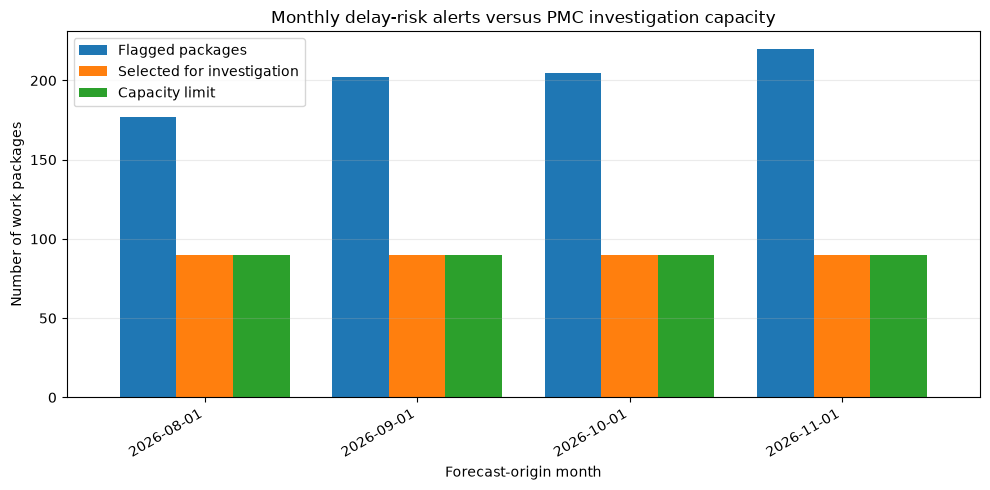

Saved: outputs_v2/risk_prioritisation_register_v2.csv


In [73]:
plot_capacity = capacity_summary.copy()
plot_capacity['month'] = plot_capacity['month'].astype(str)

plot_capacity = plot_capacity.set_index('month')[
    ['flagged_packages', 'selected_for_investigation', 'investigation_capacity']
]
ax = plot_capacity.plot(kind='bar', figsize=(10, 5), width=0.8)
ax.set_title('Monthly delay-risk alerts versus PMC investigation capacity')
ax.set_xlabel('Forecast-origin month')
ax.set_ylabel('Number of work packages')
ax.legend(['Flagged packages', 'Selected for investigation', 'Capacity limit'])
ax.grid(axis='y', alpha=0.25)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / 'v2_07_pmc_risk_prioritisation_capacity.png', dpi=150, bbox_inches='tight')
plt.show()

risk_register_path = OUTPUT_DIR / 'risk_prioritisation_register_v2.csv'
operational_risk_register.sort_values(
    ['month', 'selected_for_investigation', 'priority_score'],
    ascending=[True, False, False]
).to_csv(risk_register_path, index=False)
print('Saved:', risk_register_path.relative_to(PROJECT_ROOT))

### 2D.4 Interpretation, limitations and next data requirements

- The probability threshold is frozen from validation; it is not re-optimised on the test set.
- The ranking is performed separately for each forecast-origin month, avoiding a single queue across four different reporting periods.
- The top 30% of all packages is the monthly investigation capacity. If more than 30% are flagged, the excess remains in the flagged monitoring backlog.
- `impact_proxy_score` is a relative heuristic based on package budget and current schedule gap. It is not a contractual criticality assessment, a cost-at-risk estimate, or a probability of project overrun.
- The current synthetic dataset has no critical-path indicator, total float, predecessor/successor network, downstream activity count, forecast completion impact, or cost-at-risk. Those fields should be collected before presenting this as a fully operational prioritisation engine.
- The ranking is demonstrated on held-out test forecast origins. The target outcomes are not used to create the queue. They remain available separately for retrospective model evaluation only.

**Recommended future data additions:** `is_critical_path`, `total_float_days`, `downstream_activity_count`, `forecast_completion_impact_days`, and `cost_at_risk_cr`, each timestamped to show that it was known at the forecast origin.

In [74]:
phase2d_summary = pd.DataFrame([{
    'selected_model': best_model_name,
    'validation_selected_threshold': float(selected_threshold),
    'investigation_capacity_share': INVESTIGATION_CAPACITY_SHARE,
    'test_forecast_origins': len(operational_risk_register),
    'test_flagged_packages': int(operational_risk_register['delay_risk_flag'].sum()),
    'test_selected_for_investigation': int(operational_risk_register['selected_for_investigation'].sum()),
    'test_flagged_backlog': int((
        operational_risk_register['delay_risk_flag']
        & ~operational_risk_register['selected_for_investigation']
    ).sum()),
    'impact_score_status': 'Heuristic proxy; not validated project impact',
}])
display(phase2d_summary)
phase2d_summary.to_csv(OUTPUT_DIR / 'risk_prioritisation_summary_v2.csv', index=False)

print('Phase 2D assertions passed.')
print('Risk register:', risk_register_path.relative_to(PROJECT_ROOT))

,selected_model,validation_selected_threshold,investigation_capacity_share,test_forecast_origins,test_flagged_packages,test_selected_for_investigation,test_flagged_backlog,impact_score_status
0,Random Forest,0.280,0.300,1200,804,360,444,Heuristic proxy; not validated project impact


Phase 2D assertions passed.
Risk register: outputs_v2/risk_prioritisation_register_v2.csv


## Phase 3: Next-month cost and progress forecasting

The delay classifier answers whether a package is likely to cross the 12-day delay threshold. Project controls also needs estimates of **next-month expenditure** and **next-month physical progress**.

We will build two separate regression tasks:

1. **Cost forecasting:** predict `target_cost_next_month_cr`, the next month's actual expenditure in crore.
2. **Progress forecasting:** predict `target_progress_next_month_pct`, the next month's actual progress increment in percentage points.

The modelling grain and chronological windows remain unchanged. Model selection uses validation MAE; the test window is held out until the final evaluation. Two simple operational baselines are included for each task: the approved next-month plan and a persistence forecast using the most recent actual monthly value.

**Important:** The dataset is synthetic. These results test the modelling workflow and do not demonstrate real-world forecast accuracy.

### 3.1 Define regression targets and evaluation metrics

We use the same feature matrix as the delay classifier because all features were defined at the forecast origin and audited for target leakage in Phase 2A.

- Cost target unit: **₹ crore** (the dataset's monetary unit is crore).
- Progress target unit: **percentage points of progress during the next month**, not cumulative project progress.
- MAE is the primary model-selection metric because it is directly interpretable in the target's unit and is less sensitive to large errors than RMSE.
- RMSE, R², WAPE and mean error are reported as complementary diagnostics. WAPE is undefined if the sum of absolute actual values is zero; we guard against that case.

In [75]:
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

REGRESSION_TARGETS = {
    'cost': {
        'column': 'target_cost_next_month_cr',
        'planned_baseline': 'known_next_month_planned_cost_cr',
        'persistence_baseline': 'actual_cost_month_cr',
        'unit': '₹ crore',
    },
    'progress': {
        'column': 'target_progress_next_month_pct',
        'planned_baseline': 'known_next_month_planned_progress_pct',
        'persistence_baseline': 'actual_progress_increment_pct',
        'unit': 'percentage points',
    },
}

for task_name, config in REGRESSION_TARGETS.items():
    target = config['column']
    assert target not in FEATURE_COLUMNS
    assert config['planned_baseline'] in FEATURE_COLUMNS
    assert config['persistence_baseline'] in supervised.columns
    # Persistence baselines are observable at forecast origin; they need not all be model inputs.
    assert train_df[target].notna().all()
    assert validation_df[target].notna().all()
    assert test_df[target].notna().all()
    print(f"{task_name.title()} target: {target} | unit: {config['unit']}")

print('Regression target and baseline checks passed.')

Cost target: target_cost_next_month_cr | unit: ₹ crore
Progress target: target_progress_next_month_pct | unit: percentage points
Regression target and baseline checks passed.


### 3.2 Establish baseline forecasts

A useful model must outperform a reasonable non-ML reference. We compare:

- **Approved-plan baseline:** use the next month's planned cost or planned progress increment as the forecast.
- **Persistence baseline:** assume next month's actual monthly value will equal the most recent observed actual monthly value.

These are not necessarily the best possible construction forecasts. They are transparent benchmarks. Be careful not to confuse planned values with actual outcomes: the approved plan is an input available at the forecast origin, not the realised next-month result.

In [76]:
def regression_metrics(y_true, y_pred, model_name, task_name, split_name):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    denominator = np.abs(y_true).sum()
    wape = (np.abs(y_true - y_pred).sum() / denominator) if denominator > 0 else np.nan
    return {
        'task': task_name,
        'split': split_name,
        'model': model_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2_score(y_true, y_pred),
        'WAPE': wape,
        'mean_error_pred_minus_actual': float(np.mean(y_pred - y_true)),
    }

regression_splits = {
    'train': train_df,
    'validation': validation_df,
    'test': test_df,
}

baseline_rows = []
for task_name, config in REGRESSION_TARGETS.items():
    for split_name, frame in regression_splits.items():
        y_true = frame[config['column']].to_numpy()
        for baseline_name, prediction_column in [
            ('Approved-plan baseline', config['planned_baseline']),
            ('Persistence baseline', config['persistence_baseline']),
        ]:
            y_pred = frame[prediction_column].to_numpy()
            baseline_rows.append(regression_metrics(
                y_true, y_pred, baseline_name, task_name, split_name
            ))

regression_baseline_metrics = pd.DataFrame(baseline_rows)
display(regression_baseline_metrics.query("split == 'validation'").round(4))

,task,split,model,MAE,RMSE,R2,WAPE,mean_error_pred_minus_actual
2,cost,validation,Approved-plan baseline,0.018,0.033,0.955,0.143,-0.018
3,cost,validation,Persistence baseline,0.036,0.059,0.851,0.285,0.036
8,progress,validation,Approved-plan baseline,0.489,0.721,0.855,0.209,0.459
9,progress,validation,Persistence baseline,0.761,1.028,0.706,0.325,0.722


### 3.3 Train candidate regression models

We train two tree-based regressors for each target:

- **Random Forest Regressor:** averages many decorrelated decision trees.
- **Extra Trees Regressor:** adds more randomness to split selection, which can reduce variance and provide a useful alternative ensemble.

The preprocessing is fitted inside each pipeline using the training window only. We select the candidate with the lowest **validation MAE** for each target. We do not select models using test performance.

In [77]:
regression_model_factories = {
    'Random Forest Regressor': lambda: RandomForestRegressor(
        n_estimators=80, max_depth=12, min_samples_leaf=8, max_features=0.6,
        random_state=RANDOM_STATE, n_jobs=1,
    ),
    'Extra Trees Regressor': lambda: ExtraTreesRegressor(
        n_estimators=80, max_depth=12, min_samples_leaf=8, max_features=0.6,
        random_state=RANDOM_STATE, n_jobs=1,
    ),
}

regression_candidates = {}
regression_validation_predictions = {}
regression_validation_rows = []

for task_name, config in REGRESSION_TARGETS.items():
    y_train_reg = train_df[config['column']].astype(float)
    y_validation_reg = validation_df[config['column']].astype(float)
    regression_candidates[task_name] = {}
    regression_validation_predictions[task_name] = {}

    for model_name, model_factory in regression_model_factories.items():
        model_pipeline = Pipeline(steps=[
            ('preprocess', clone(preprocessor)),
            ('regressor', model_factory()),
        ])
        model_pipeline.fit(X_train, y_train_reg)
        validation_prediction = model_pipeline.predict(X_validation)
        regression_candidates[task_name][model_name] = model_pipeline
        regression_validation_predictions[task_name][model_name] = validation_prediction
        regression_validation_rows.append(regression_metrics(
            y_validation_reg, validation_prediction, model_name, task_name, 'validation'
        ))

regression_validation_model_comparison = pd.DataFrame(regression_validation_rows).sort_values(
    ['task', 'MAE'], ascending=[True, True]
).reset_index(drop=True)
display(regression_validation_model_comparison.round(4))

,task,split,model,MAE,RMSE,R2,WAPE,mean_error_pred_minus_actual
0,cost,validation,Random Forest Regressor,0.008,0.015,0.990,0.064,0.001
1,cost,validation,Extra Trees Regressor,0.012,0.024,0.976,0.090,0.006
2,progress,validation,Random Forest Regressor,0.300,0.461,0.941,0.128,0.189
3,progress,validation,Extra Trees Regressor,0.695,0.829,0.809,0.296,0.637


### 3.4 Select each model using validation MAE

The winning model is selected independently for cost and progress. This is intentional: expenditure and physical progress have different distributions, units and error behaviour, so one algorithm does not need to win both tasks.

In [78]:
selected_regression_models = {}
selected_regression_model_names = {}
selection_rows = []

for task_name in REGRESSION_TARGETS:
    task_results = regression_validation_model_comparison.query('task == @task_name')
    winner = task_results.sort_values('MAE').iloc[0]
    winner_name = winner['model']
    selected_regression_model_names[task_name] = winner_name
    selected_regression_models[task_name] = regression_candidates[task_name][winner_name]
    selection_rows.append({
        'task': task_name,
        'selected_model': winner_name,
        'validation_MAE': winner['MAE'],
        'validation_RMSE': winner['RMSE'],
        'validation_R2': winner['R2'],
    })

regression_model_selection = pd.DataFrame(selection_rows)
display(regression_model_selection.round(4))

,task,selected_model,validation_MAE,validation_RMSE,validation_R2
0,cost,Random Forest Regressor,0.008,0.015,0.990
1,progress,Random Forest Regressor,0.300,0.461,0.941


### 3.5 Refit selected models and evaluate once on the held-out test window

After selecting the model family on validation data, we refit that model using the combined train + validation periods. This uses more historical observations while keeping the test period untouched. We then evaluate on the test set exactly once for the final comparison.

The test metrics are the final retrospective estimate for this synthetic holdout. Do not repeatedly change the model after inspecting test results and continue calling the same period an untouched test set.

In [79]:
train_validation_df = pd.concat([train_df, validation_df], axis=0).sort_values(
    ['month_index', 'project_id', 'work_category']
).copy()
X_train_validation = train_validation_df[FEATURE_COLUMNS].copy()

final_regression_models = {}
regression_test_predictions = {}
regression_test_rows = []

for task_name, config in REGRESSION_TARGETS.items():
    selected_name = selected_regression_model_names[task_name]
    model_factory = regression_model_factories[selected_name]
    final_pipeline = Pipeline(steps=[
        ('preprocess', clone(preprocessor)),
        ('regressor', model_factory()),
    ])
    final_pipeline.fit(X_train_validation, train_validation_df[config['column']].astype(float))
    test_prediction = final_pipeline.predict(X_test)
    final_regression_models[task_name] = final_pipeline
    regression_test_predictions[task_name] = test_prediction

    y_test_reg = test_df[config['column']].astype(float)
    regression_test_rows.append(regression_metrics(
        y_test_reg, test_prediction, selected_name, task_name, 'test'
    ))
    for baseline_name, prediction_column in [
        ('Approved-plan baseline', config['planned_baseline']),
        ('Persistence baseline', config['persistence_baseline']),
    ]:
        regression_test_rows.append(regression_metrics(
            y_test_reg, test_df[prediction_column], baseline_name, task_name, 'test'
        ))

regression_test_metrics = pd.DataFrame(regression_test_rows)
display(regression_test_metrics.round(4))

for task_name, config in REGRESSION_TARGETS.items():
    assert np.isfinite(regression_test_predictions[task_name]).all()
    if task_name == 'cost':
        assert (regression_test_predictions[task_name] >= 0).all(), 'Cost predictions must be non-negative.'
    if task_name == 'progress':
        assert (regression_test_predictions[task_name] >= 0).all(), 'Progress-increment predictions must be non-negative.'
print('Final regression predictions are finite and satisfy non-negative domain checks.')

,task,split,model,MAE,RMSE,R2,WAPE,mean_error_pred_minus_actual
0,cost,test,Random Forest Regressor,0.002,0.006,0.992,0.069,-0.001
1,cost,test,Approved-plan baseline,0.004,0.013,0.961,0.164,-0.004
2,cost,test,Persistence baseline,0.018,0.039,0.664,0.687,0.018
3,progress,test,Random Forest Regressor,0.057,0.153,0.971,0.130,0.010
4,progress,test,Approved-plan baseline,0.100,0.268,0.910,0.228,0.094
5,progress,test,Persistence baseline,0.326,0.618,0.521,0.748,0.324


Final regression predictions are finite and satisfy non-negative domain checks.


### 3.6 Compare forecasts with actual outcomes

The plots below compare actual next-month outcomes with model predictions. A good model should generally track the diagonal reference line. These are pooled test observations; because each project-work-category series contributes several months, the points are not statistically independent.

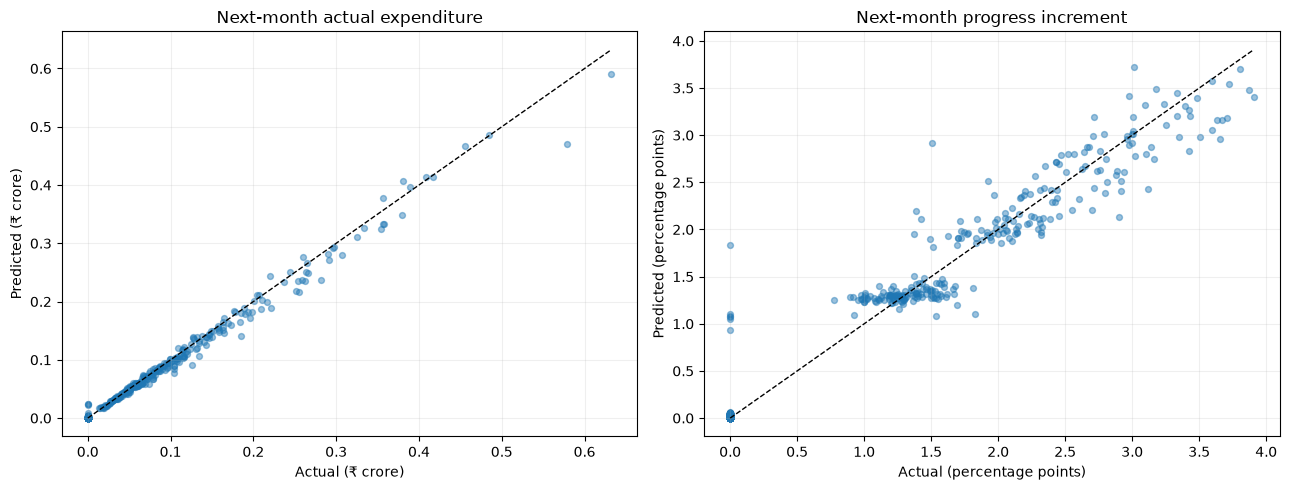

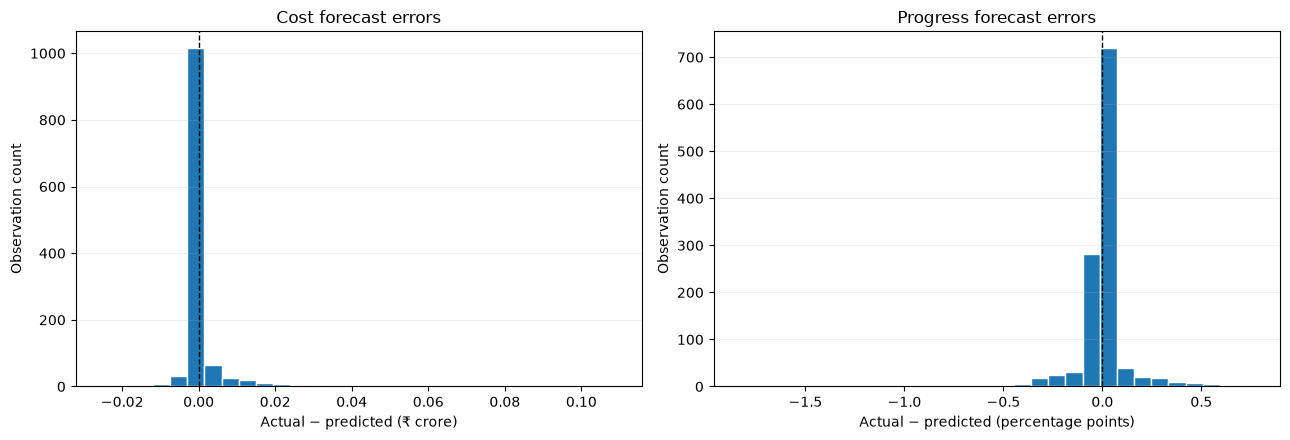

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, task_name, title, unit in [
    (axes[0], 'cost', 'Next-month actual expenditure', '₹ crore'),
    (axes[1], 'progress', 'Next-month progress increment', 'percentage points'),
]:
    config = REGRESSION_TARGETS[task_name]
    actual = test_df[config['column']].to_numpy(dtype=float)
    predicted = regression_test_predictions[task_name]
    ax.scatter(actual, predicted, alpha=0.45, s=18)
    lower = min(float(np.min(actual)), float(np.min(predicted)))
    upper = max(float(np.max(actual)), float(np.max(predicted)))
    ax.plot([lower, upper], [lower, upper], linestyle='--', color='black', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel(f'Actual ({unit})')
    ax.set_ylabel(f'Predicted ({unit})')
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / 'v2_06_regression_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, task_name, title, unit in [
    (axes[0], 'cost', 'Cost forecast errors', '₹ crore'),
    (axes[1], 'progress', 'Progress forecast errors', 'percentage points'),
]:
    actual = test_df[REGRESSION_TARGETS[task_name]['column']].to_numpy(dtype=float)
    residual = actual - regression_test_predictions[task_name]
    ax.hist(residual, bins=30, edgecolor='white')
    ax.axvline(0, color='black', linestyle='--', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel(f'Actual − predicted ({unit})')
    ax.set_ylabel('Observation count')
    ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / 'v2_07_regression_residuals.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.7 Inspect month-level forecast performance

A pooled metric can hide deterioration in particular months. We therefore report test MAE by target month. This is especially important for time-dependent forecasting: model errors may change as project conditions evolve.

In [81]:
monthly_error_rows = []
for task_name, config in REGRESSION_TARGETS.items():
    actual = test_df[config['column']].to_numpy(dtype=float)
    predicted = regression_test_predictions[task_name]
    monthly_frame = pd.DataFrame({
        'target_month': test_df['target_month'].to_numpy(),
        'actual': actual,
        'predicted': predicted,
    })
    for target_month, month_frame in monthly_frame.groupby('target_month'):
        monthly_error_rows.append({
            'task': task_name,
            'target_month': target_month,
            'observations': len(month_frame),
            'MAE': mean_absolute_error(month_frame['actual'], month_frame['predicted']),
            'RMSE': mean_squared_error(month_frame['actual'], month_frame['predicted']) ** 0.5,
        })

regression_monthly_errors = pd.DataFrame(monthly_error_rows)
display(regression_monthly_errors.round(4))

/var/folders/x5/lg6mzwt166v69knh3yc023r80000gn/T/ipykernel_45057/1258482807.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(regression_monthly_errors.round(4))


,task,target_month,observations,MAE,RMSE
0,cost,2026-09-01,300,0.003,0.007
1,cost,2026-10-01,300,0.002,0.009
2,cost,2026-11-01,300,0.001,0.004
3,cost,2026-12-01,300,0.001,0.004
4,progress,2026-09-01,300,0.098,0.204
5,progress,2026-10-01,300,0.069,0.181
6,progress,2026-11-01,300,0.039,0.126
7,progress,2026-12-01,300,0.020,0.056


### 3.8 Save Phase 3 artifacts and audit the forecast outputs

The forecast export contains the forecast origin, target month, actual target (for retrospective evaluation), model prediction and baseline forecasts. Because it includes actual target outcomes, it is an **evaluation artifact**, not a live operational forecast feed. A production scoring export would omit the actual target columns until outcomes are observed.

In [82]:
cost_forecast_evaluation = test_df[[
    'project_id', 'project_name', 'contractor', 'work_category', 'month', 'target_month',
    'target_cost_next_month_cr', 'known_next_month_planned_cost_cr',
    'actual_cost_month_cr',
]].copy()
cost_forecast_evaluation = cost_forecast_evaluation.rename(columns={
    'target_cost_next_month_cr': 'actual_cost_next_month_cr',
    'known_next_month_planned_cost_cr': 'planned_cost_baseline_cr',
    'actual_cost_month_cr': 'persistence_cost_baseline_cr',
})
cost_forecast_evaluation['predicted_cost_next_month_cr'] = regression_test_predictions['cost']

progress_forecast_evaluation = test_df[[
    'project_id', 'project_name', 'contractor', 'work_category', 'month', 'target_month',
    'target_progress_next_month_pct', 'known_next_month_planned_progress_pct',
    'actual_progress_increment_pct',
]].copy()
progress_forecast_evaluation = progress_forecast_evaluation.rename(columns={
    'target_progress_next_month_pct': 'actual_progress_next_month_pct',
    'known_next_month_planned_progress_pct': 'planned_progress_baseline_pct',
    'actual_progress_increment_pct': 'persistence_progress_baseline_pct',
})
progress_forecast_evaluation['predicted_progress_next_month_pct'] = regression_test_predictions['progress']

phase3_dir = OUTPUT_DIR
phase3_validation_path = phase3_dir / 'regression_validation_model_comparison_v2.csv'
phase3_baseline_path = phase3_dir / 'regression_baseline_metrics_v2.csv'
phase3_test_path = phase3_dir / 'regression_test_metrics_v2.csv'
phase3_monthly_path = phase3_dir / 'regression_monthly_errors_v2.csv'
phase3_cost_path = phase3_dir / 'cost_forecast_test_evaluation_v2.csv'
phase3_progress_path = phase3_dir / 'progress_forecast_test_evaluation_v2.csv'

regression_validation_model_comparison.to_csv(phase3_validation_path, index=False)
regression_baseline_metrics.to_csv(phase3_baseline_path, index=False)
regression_test_metrics.to_csv(phase3_test_path, index=False)
regression_monthly_errors.to_csv(phase3_monthly_path, index=False)
cost_forecast_evaluation.to_csv(phase3_cost_path, index=False)
progress_forecast_evaluation.to_csv(phase3_progress_path, index=False)

phase3_summary_rows = []
for task_name, config in REGRESSION_TARGETS.items():
    selected_test_row = regression_test_metrics.loc[
        (regression_test_metrics['task'] == task_name)
        & (regression_test_metrics['model'] == selected_regression_model_names[task_name])
    ].iloc[0]
    phase3_summary_rows.append({
        'task': task_name,
        'selected_model': selected_regression_model_names[task_name],
        'test_MAE': selected_test_row['MAE'],
        'test_RMSE': selected_test_row['RMSE'],
        'test_R2': selected_test_row['R2'],
        'unit': config['unit'],
    })
phase3_summary = pd.DataFrame(phase3_summary_rows)
display(phase3_summary.round(4))
phase3_summary.to_csv(phase3_dir / 'regression_forecasting_summary_v2.csv', index=False)

print('Saved Phase 3 artifacts:')
for path in [phase3_validation_path, phase3_baseline_path, phase3_test_path,
             phase3_monthly_path, phase3_cost_path, phase3_progress_path,
             phase3_dir / 'regression_forecasting_summary_v2.csv']:
    print('-', path.relative_to(PROJECT_ROOT))

assert len(cost_forecast_evaluation) == len(test_df)
assert len(progress_forecast_evaluation) == len(test_df)
assert not cost_forecast_evaluation['predicted_cost_next_month_cr'].isna().any()
assert not progress_forecast_evaluation['predicted_progress_next_month_pct'].isna().any()
print('Phase 3 export and row-count checks passed.')

,task,selected_model,test_MAE,test_RMSE,test_R2,unit
0,cost,Random Forest Regressor,0.002,0.006,0.992,₹ crore
1,progress,Random Forest Regressor,0.057,0.153,0.971,percentage points


Saved Phase 3 artifacts:
- outputs_v2/regression_validation_model_comparison_v2.csv
- outputs_v2/regression_baseline_metrics_v2.csv
- outputs_v2/regression_test_metrics_v2.csv
- outputs_v2/regression_monthly_errors_v2.csv
- outputs_v2/cost_forecast_test_evaluation_v2.csv
- outputs_v2/progress_forecast_test_evaluation_v2.csv
- outputs_v2/regression_forecasting_summary_v2.csv
Phase 3 export and row-count checks passed.


### Phase 3 checkpoint — explain the model and its business meaning

1. Why is next month's approved planned cost a fair baseline, but next month's actual cost not a valid feature?
2. If cost MAE is 0.002 crore, what is that error in rupees? (1 crore = ₹10,000,000.)
3. Why should we compare the regression model against both the approved-plan and persistence baselines?
4. Why is predicting a monthly progress increment different from predicting cumulative progress?
5. If the model has a strong pooled test R² but a much higher MAE in one target month, what would you investigate before recommending it to a project team?

**Interpretation guardrail:** All metrics are based on a synthetic dataset generated by known simulation rules. They validate code paths and modelling discipline, not performance on real construction projects.